# Phân tích bộ dữ liệu Loan Default

**Nguồn dữ liệu:** [Loan Default Dataset - Kaggle](https://www.kaggle.com/datasets/yasserh/loan-default-dataset)

**Quy mô:** 148.670 hồ sơ khoản vay với 34 thuộc tính.

## Nội dung

- **Thiết lập môi trường:** Chuẩn bị thư viện và tải dữ liệu trên Google Colab.
- **Giai đoạn 1 - Khám phá dữ liệu:** Kiểm tra cấu trúc, dữ liệu thiếu và tính nhất quán.
- **Giai đoạn 2 - Tiền xử lý:** Làm sạch dữ liệu, kiểm tra ngoại lệ và giải thích phương pháp xử lý.
- **Giai đoạn 3 - Phân tích:** Kiểm định giả thuyết, trực quan hóa và nhận xét kết quả.
- **Giai đoạn 4 - Kết luận:** Tổng hợp phát hiện, khuyến nghị và giới hạn nghiên cứu.

## Quy ước về Status

- **Status = 0:** Khoản vay không vỡ nợ (*Non-default*).
- **Status = 1:** Khoản vay vỡ nợ (*Default*).

Cách phân loại này được tham khảo từ các dự án sử dụng cùng bộ dữ liệu; Kaggle chưa cung cấp định nghĩa chính thức cho hai nhãn.

## Giai đoạn 0. Thiết lập môi trường và tải dữ liệu

Dữ liệu được tải theo thứ tự sau:

1. Sử dụng file `Loan_Default.csv` nếu đã có sẵn.
2. Nếu không tìm thấy, tải từ Kaggle bằng `kagglehub`.
3. Nếu không tải được từ Kaggle, tải file CSV lên Colab thủ công.

In [ ]:
# Import các thư viện dùng trong toàn bộ notebook
import os
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.preprocessing import RobustScaler, StandardScaler

# Cấu hình hiển thị bảng và biểu đồ
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [ ]:
# Các hàm hỗ trợ kiểm định thống kê và vẽ biểu đồ
def compute_cramers_v(table, chi2):
    # Tính mức độ liên hệ bằng Cramér's V
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

def label_effect(value):
    # Phân loại mức độ liên hệ theo các ngưỡng tham khảo
    value = abs(value)
    if value < 0.1:
        return "Không đáng kể"
    if value < 0.3:
        return "Nhỏ"
    if value < 0.5:
        return "Trung bình"
    return "Lớn"

def chi_square_report(table):
    # Kiểm định Chi-square và đánh giá mức độ liên hệ giữa hai biến
    chi2, p, dof, expected = chi2_contingency(table)
    v = compute_cramers_v(table, chi2)
    return {
        "Chi-square": round(chi2, 4), "df": dof, "p-value": p,
        "Cramér's V": round(v, 4), "Mức độ": label_effect(v),
        "Tần số kỳ vọng nhỏ nhất": round(expected.min(), 1),
        "% ô có kỳ vọng < 5": round((expected < 5).mean() * 100, 1),
    }

def mann_whitney_report(x0, x1):
    # So sánh hai nhóm bằng kiểm định Mann-Whitney U
    x0, x1 = pd.Series(x0).dropna(), pd.Series(x1).dropna()
    u, p = mannwhitneyu(x0, x1, alternative="two-sided")
    r = 2 * u / (len(x0) * len(x1)) - 1
    return {
        "U": u, "p-value": p, "Rank-biserial r": round(r, 4), "Mức độ": label_effect(r),
        "n (Status=0)": len(x0), "n (Status=1)": len(x1),
        "Median (Status=0)": x0.median(), "Median (Status=1)": x1.median(),
    }

def iqr_bounds(series, k=1.5):
    # Tính ngưỡng dưới và ngưỡng trên để phát hiện giá trị ngoại lệ
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, q1 - k * iqr, q3 + k * iqr

def plot_status_rate(rate, counts, title, xlabel, overall, ax=None, highlight_missing=False):
    # Vẽ biểu đồ tỷ lệ Status = 1 và đường tỷ lệ chung
    # Tô màu xám cho nhóm thiếu dữ liệu nếu có
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    colors = ["steelblue"] * len(rate)
    if highlight_missing:
        colors[-1] = "grey"
    bars = ax.bar(rate.index.astype(str), rate.values, color=colors)
    line = ax.axhline(overall, color="red", linestyle="--", label=f"Tỷ lệ chung ({overall:.2f}%)")
    for bar, value, n in zip(bars, rate.values, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.8, f"{value:.2f}%\nn={n:,}",
                ha="center", va="bottom", fontsize=8,
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1))
    handles = [Patch(color="steelblue", label="Tỷ lệ Status = 1 của nhóm")]
    if highlight_missing:
        handles.append(Patch(color="grey", label="Nhóm thiếu dữ liệu"))
    handles.append(line)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Tỷ lệ Status = 1 (%)")
    ax.set_ylim(0, max(rate.max(), overall) * 1.3)
    ax.legend(handles=handles, loc="upper left", fontsize=8)
    return ax


def format_p(p):
    # Định dạng p-value để dễ đọc
    return "< 1e-300" if p < 1e-300 else f"{p:.3e}"

In [ ]:
# Tải dữ liệu từ máy hoặc Kaggle
DATA_FILE = "Loan_Default.csv"
KAGGLE_DATASET = "yasserh/loan-default-dataset"


def load_loan_default():
    # Kiểm tra file có sẵn
    for path in [DATA_FILE, os.path.join("/content", DATA_FILE)]:
        if os.path.exists(path):
            print("Đọc dữ liệu từ file cục bộ:", path)
            return pd.read_csv(path)

    # Tải dữ liệu từ Kaggle
    try:
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_DATASET)
        path = os.path.join(folder, DATA_FILE)
        print("Đọc dữ liệu từ KaggleHub:", path)
        return pd.read_csv(path)
    except Exception as err:
        print("Không tải được bằng KaggleHub:", err)

    # Tải file thủ công trên Colab nếu các cách trên không thành công
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Không tìm thấy Loan_Default.csv. Hãy đặt file cùng thư mục với notebook.")
    print("Hãy chọn file Loan_Default.csv từ máy tính")
    uploaded = files.upload()
    return pd.read_csv(io.BytesIO(uploaded[DATA_FILE]))


# Đọc dữ liệu gốc
df = load_loan_default()

# Xem 5 dòng đầu tiên
df.head()

Using Colab cache for faster access to the 'loan-default-dataset' dataset.
Đọc dữ liệu từ KaggleHub: /kaggle/input/loan-default-dataset/Loan_Default.csv


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,Neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,Secured_by,total_units,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,116500,NaN,NaN,NaN,360.0,not_neg,not_int,not_lpsm,118000.0,sb,pr,home,1U,1740.0,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,206500,NaN,NaN,NaN,360.0,not_neg,not_int,lpsm,NaN,sb,pr,home,1U,4980.0,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,406500,4.56,0.2000,595.0,360.0,neg_amm,not_int,not_lpsm,508000.0,sb,pr,home,1U,9480.0,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,456500,4.25,0.6810,NaN,360.0,not_neg,not_int,not_lpsm,658000.0,sb,pr,home,1U,11880.0,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,696500,4.00,0.3042,0.0,360.0,not_neg,not_int,not_lpsm,758000.0,sb,pr,home,1U,10440.0,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


# Giai đoạn 1. Thu thập và đánh giá dữ liệu ban đầu

## 1.1. Mục tiêu phân tích

Giai đoạn này tập trung vào việc tìm hiểu bộ dữ liệu trước khi tiến hành làm sạch và phân tích.

Các mục tiêu chính:

1. Kiểm tra số lượng dòng, cột và kiểu dữ liệu của từng thuộc tính.
2. Xác định các giá trị bị thiếu, dữ liệu trùng lặp và những điểm không nhất quán.
3. Tìm hiểu các thuộc tính để chuẩn bị cho bước tiền xử lý và phân tích ở những giai đoạn tiếp theo.

In [ ]:
# Kiểm tra số lượng quan sát và thuộc tính của bộ dữ liệu
df.shape

(148670, 34)

In [ ]:
# Kiểm tra cấu trúc và kiểu dữ liệu của từng thuộc tính
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

In [ ]:
# Kiểm tra phạm vi thời gian và tính liên tục của mã ID
print("Các giá trị của year:", df["year"].unique())
print("ID nhỏ nhất – lớn nhất:", df["ID"].min(), "–", df["ID"].max())
print("ID tăng dần liên tục:", (df["ID"].diff().dropna() == 1).all())

# Đếm số thuộc tính theo kiểu dữ liệu
df.dtypes.value_counts()

Các giá trị của year: [2019]
ID nhỏ nhất – lớn nhất: 24890 – 173559
ID tăng dần liên tục: True


,count
object,21
float64,8
int64,5


**Nhận xét:** Bộ dữ liệu gồm 148.670 dòng và 34 cột, trong đó có 13 cột dữ liệu số và 21 cột dữ liệu dạng chuỗi. Các mã `ID` tăng liên tục từ 24.890 đến 173.559. Cột `year` chỉ chứa giá trị 2019 nên không thể phân tích xu hướng theo thời gian.

In [ ]:
# Thống kê các cột dữ liệu số, không tính ID và year
numeric_cols = df.select_dtypes(include="number").columns.drop(["ID", "year"])
df[numeric_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
loan_amount,148670.0,331117.74,183909.31,16500.00,66500.00,196500.00,296500.00,436500.00,856500.00,3576500.00
rate_of_interest,112231.0,4.05,0.56,0.00,2.88,3.62,3.99,4.38,5.50,8.00
Interest_rate_spread,112031.0,0.44,0.51,-3.64,-0.68,0.08,0.39,0.78,1.62,3.36
Upfront_charges,109028.0,3225.00,3251.12,0.00,0.00,581.49,2596.45,4812.50,14297.05,60000.00
term,148629.0,335.14,58.41,96.00,180.00,360.00,360.00,360.00,360.00,360.00
property_value,133572.0,497893.47,359935.32,8000.00,88000.00,268000.00,418000.00,628000.00,1808000.00,16508000.00
income,139520.0,6957.34,6496.59,0.00,600.00,3720.00,5760.00,8520.00,26640.00,578580.00
Credit_Score,148670.0,699.79,115.88,500.00,504.00,599.00,699.00,800.00,897.00,900.00
LTV,133572.0,72.75,39.97,0.97,19.61,60.47,75.14,86.18,102.76,7831.25
Status,148670.0,0.25,0.43,0.00,0.00,0.00,0.00,0.00,1.00,1.00


**Nhận xét:**

- `loan_amount`, `income` và `property_value` có giá trị trung bình cao hơn trung vị, đồng thời giá trị lớn nhất vượt xa phân vị 99%. Điều này cho thấy dữ liệu có xu hướng lệch phải và cần kiểm tra các giá trị ngoại lệ.
- `LTV` có giá trị lớn nhất lên tới 7.831,25%, trong khi phân vị 99% chỉ khoảng 102,76%. Đây là giá trị bất thường cần kiểm tra kỹ hơn.
- `income` và `rate_of_interest` đều có giá trị nhỏ nhất bằng 0, cần xem xét tính hợp lý.
- `Credit_Score` nằm trong khoảng 500-900, với trung bình khoảng 700. `dtir1` dao động từ 5 đến 61.

Các giá trị bất thường sẽ được kiểm tra chi tiết ở Giai đoạn 2.

## 1.2. Tỷ lệ dữ liệu thiếu

In [ ]:
# Tính số lượng và tỷ lệ dữ liệu thiếu của từng cột
missing_values = pd.DataFrame({
    "Số lượng thiếu": df.isnull().sum(),
    "Tỷ lệ thiếu (%)": (df.isnull().mean() * 100).round(2)
})

# Hiển thị bảng kết quả
display(missing_values)

,Số lượng thiếu,Tỷ lệ thiếu (%)
ID,0,0.00
year,0,0.00
loan_limit,3344,2.25
Gender,0,0.00
approv_in_adv,908,0.61
loan_type,0,0.00
loan_purpose,134,0.09
Credit_Worthiness,0,0.00
open_credit,0,0.00
business_or_commercial,0,0.00


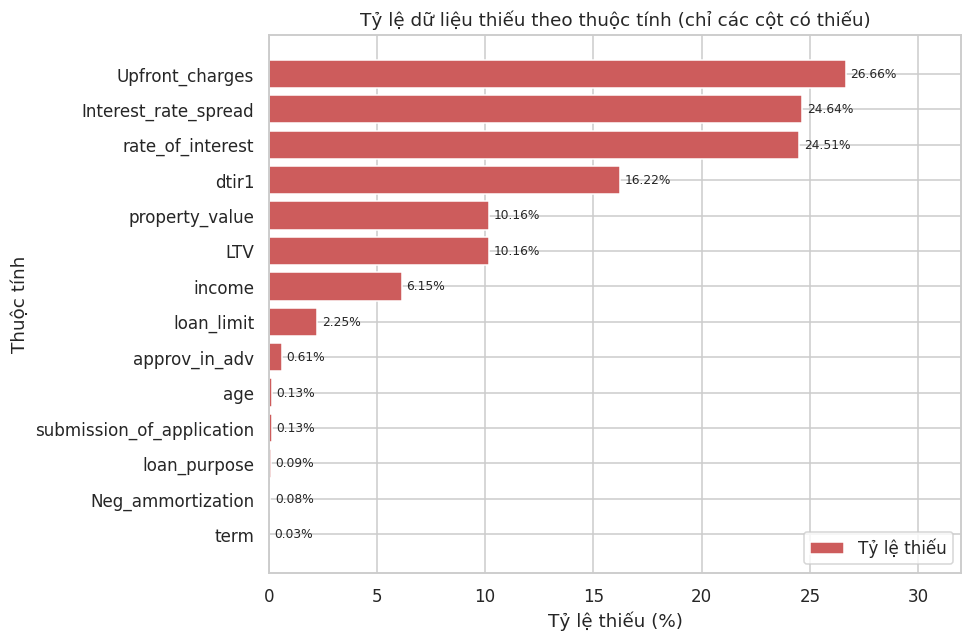

In [ ]:
# Vẽ biểu đồ tỷ lệ dữ liệu thiếu
missing_plot = missing_values[missing_values["Số lượng thiếu"] > 0].sort_values("Tỷ lệ thiếu (%)")

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(missing_plot.index, missing_plot["Tỷ lệ thiếu (%)"], color="indianred", label="Tỷ lệ thiếu")
ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=8)

# Thêm tiêu đề và tên các trục
ax.set_title("Tỷ lệ dữ liệu thiếu theo thuộc tính (chỉ các cột có thiếu)")
ax.set_xlabel("Tỷ lệ thiếu (%)")
ax.set_ylabel("Thuộc tính")
ax.set_xlim(0, 32)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Nhận xét:**

Có 14 trong tổng số 34 cột chứa dữ liệu thiếu. Trong đó, `Upfront_charges` có tỷ lệ thiếu cao nhất (26,66%), tiếp theo là `Interest_rate_spread` (24,64%) và `rate_of_interest` (24,51%).

Các cột `dtir1`, `property_value`, `LTV` và `income` cũng có tỷ lệ thiếu đáng chú ý, từ 6,15% đến 16,22%. Những cột còn lại thiếu dưới 2,5%.

Đáng chú ý, tỷ lệ thiếu của `Interest_rate_spread` bằng đúng tỷ lệ `Status = 1` (24,64%). Ngoài ra, `property_value` và `LTV` có cùng số lượng giá trị thiếu. Những điểm này sẽ được kiểm tra kỹ hơn ở Giai đoạn 2.

## 1.3. Dữ liệu trùng lặp

In [ ]:
# Kiểm tra các dòng trùng lặp
duplicate_count = df.duplicated().sum()
print("Số bản ghi trùng lặp:", duplicate_count)

Số bản ghi trùng lặp: 0


In [ ]:
# Kiểm tra ID trùng lặp
duplicate_id = df["ID"].duplicated().sum()
print("Số ID trùng lặp:", duplicate_id)

# Kiểm tra các dòng giống nhau khi không tính ID
duplicate_without_id = df.drop(columns=["ID"]).duplicated().sum()
print("Số bản ghi trùng lặp (không tính ID):", duplicate_without_id)

Số ID trùng lặp: 0
Số bản ghi trùng lặp (không tính ID): 0


**Nhận xét:** Không phát hiện bản ghi trùng lặp hoặc mã `ID` bị trùng, kể cả khi kiểm tra dữ liệu không có cột `ID`. Tuy nhiên, do không có thông tin định danh người vay nên chưa thể xác định một người có nhiều khoản vay trong bộ dữ liệu hay không.

## 1.4. Các giá trị phân loại

In [ ]:
# Kiểm tra các giá trị khác nhau trong từng thuộc tính phân loại
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


loan_limit:
['cf' nan 'ncf']

Gender:
['Sex Not Available' 'Male' 'Joint' 'Female']

approv_in_adv:
['nopre' 'pre' nan]

loan_type:
['type1' 'type2' 'type3']

loan_purpose:
['p1' 'p4' 'p3' 'p2' nan]

Credit_Worthiness:
['l1' 'l2']

open_credit:
['nopc' 'opc']

business_or_commercial:
['nob/c' 'b/c']

Neg_ammortization:
['not_neg' 'neg_amm' nan]

interest_only:
['not_int' 'int_only']

lump_sum_payment:
['not_lpsm' 'lpsm']

construction_type:
['sb' 'mh']

occupancy_type:
['pr' 'sr' 'ir']

Secured_by:
['home' 'land']

total_units:
['1U' '2U' '3U' '4U']

credit_type:
['EXP' 'EQUI' 'CRIF' 'CIB']

co-applicant_credit_type:
['CIB' 'EXP']

age:
['25-34' '55-64' '35-44' '45-54' '65-74' '>74' '<25' nan]

submission_of_application:
['to_inst' 'not_inst' nan]

Region:
['south' 'North' 'central' 'North-East']

Security_Type:
['direct' 'Indriect']


**Nhận xét:**

- Cột `Security_Type` có giá trị `Indriect` bị sai chính tả, còn `Region` có cách viết hoa không thống nhất giữa các khu vực. Những lỗi này cần được sửa ở Giai đoạn 2.
- Một số thuộc tính sử dụng mã viết tắt như `type1`, `p1`, `l1` và `cf`. Do chưa có thông tin giải thích đầy đủ nên các mã này được giữ nguyên.
- Cột `Gender` có giá trị `Sex Not Available`, thể hiện trường hợp không có thông tin giới tính. Giá trị này khác với `NaN` nên không cần thay thế.

## 1.5. Data Dictionary (34 thuộc tính)

Bảng dưới đây trình bày tên, kiểu dữ liệu và ý nghĩa của 34 thuộc tính trong bộ dữ liệu Loan Default. Một số thuộc tính sử dụng mã viết tắt chưa được Kaggle giải thích rõ nên được giữ nguyên theo dữ liệu gốc.

In [ ]:
# Tạo mô tả cho 34 thuộc tính trong bộ dữ liệu
dictionary_info = {
    "ID": "Mã định danh khoản vay",
    "year": "Năm ghi nhận khoản vay",
    "loan_limit": "Giới hạn khoản vay (cf/ncf)",
    "Gender": "Thông tin giới tính hoặc hồ sơ vay chung (Male/Female/Joint/Sex Not Available)",
    "approv_in_adv": "Phê duyệt trước khoản vay (pre/nopre)",
    "loan_type": "Loại khoản vay (type1/type2/type3)",
    "loan_purpose": "Mục đích vay (p1/p2/p3/p4)",
    "Credit_Worthiness": "Mức độ tín nhiệm (l1/l2)",
    "open_credit": "Loại tín dụng mở (opc/nopc)",
    "business_or_commercial": "Khoản vay kinh doanh hoặc thương mại (b/c, nob/c)",
    "loan_amount": "Số tiền vay",
    "rate_of_interest": "Lãi suất khoản vay",
    "Interest_rate_spread": "Chênh lệch lãi suất",
    "Upfront_charges": "Phí trả trước",
    "term": "Thời hạn vay",
    "Neg_ammortization": "Khoản vay có hoặc không có khấu hao âm (neg_amm/not_neg)",
    "interest_only": "Khoản vay có hoặc không có điều khoản chỉ trả lãi (int_only/not_int)",
    "lump_sum_payment": "Khoản vay có hoặc không có khoản thanh toán một lần (lpsm/not_lpsm)",
    "property_value": "Giá trị tài sản",
    "construction_type": "Loại công trình (sb/mh)",
    "occupancy_type": "Mục đích sử dụng bất động sản (pr/sr/ir)",
    "Secured_by": "Tài sản bảo đảm (home/land)",
    "total_units": "Số đơn vị nhà ở (1U–4U)",
    "income": "Thu nhập người vay",
    "credit_type": "Loại hoặc nguồn thông tin tín dụng (EXP/EQUI/CRIF/CIB)",
    "Credit_Score": "Điểm tín dụng",
    "co-applicant_credit_type": "Loại hoặc nguồn thông tin tín dụng của người đồng vay (CIB/EXP)",
    "age": "Nhóm tuổi người vay",
    "submission_of_application": "Hình thức nộp hồ sơ (to_inst/not_inst)",
    "LTV": "Tỷ lệ khoản vay so với giá trị tài sản (%)",
    "Region": "Khu vực địa lý",
    "Security_Type": "Hình thức bảo đảm (direct/Indriect)",
    "Status": "Trạng thái khoản vay (0: Không vỡ nợ; 1: Vỡ nợ)",
    "dtir1": "Tỷ lệ nợ trên thu nhập",
}

# Tạo bảng Data Dictionary
data_dictionary = pd.DataFrame({
    "Thuộc tính": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị khác nhau": df.nunique().values,
    "Tỷ lệ thiếu (%)": (df.isnull().mean() * 100).round(2).values,
    "Mô tả": [dictionary_info[col] for col in df.columns]
})

# Hiển thị đầy đủ bảng
pd.set_option("display.max_colwidth", 100)
display(data_dictionary)

,Thuộc tính,Kiểu dữ liệu,Số giá trị khác nhau,Tỷ lệ thiếu (%),Mô tả
0,ID,int64,148670,0.00,Mã định danh khoản vay
1,year,int64,1,0.00,Năm ghi nhận khoản vay
2,loan_limit,object,2,2.25,Giới hạn khoản vay (cf/ncf)
3,Gender,object,4,0.00,Thông tin giới tính hoặc hồ sơ vay chung (Male/Female/Joint/Sex Not Available)
4,approv_in_adv,object,2,0.61,Phê duyệt trước khoản vay (pre/nopre)
5,loan_type,object,3,0.00,Loại khoản vay (type1/type2/type3)
6,loan_purpose,object,4,0.09,Mục đích vay (p1/p2/p3/p4)
7,Credit_Worthiness,object,2,0.00,Mức độ tín nhiệm (l1/l2)
8,open_credit,object,2,0.00,Loại tín dụng mở (opc/nopc)
9,business_or_commercial,object,2,0.00,"Khoản vay kinh doanh hoặc thương mại (b/c, nob/c)"


**Các biến chính được sử dụng trong phân tích:**

- **Biến mục tiêu:** `Status`.
- **Thông tin tài chính:** `income`, `Credit_Score`, `dtir1`.
- **Đặc điểm khoản vay:** `loan_amount`, `loan_type`, `Neg_ammortization`, `lump_sum_payment`.
- **Thông tin tài sản:** `property_value`, `LTV`.
- **Thông tin người vay và khu vực:** `age`, `Gender`, `Region`.

Ngoài ra, các biến liên quan đến lãi suất và phí sẽ được kiểm tra kỹ hơn do có nhiều giá trị thiếu.


## 1.6. Kiểm tra tính nhất quán giữa các cột

Phần này kiểm tra xem các cột có chứa thông tin trùng nhau hoặc có giá trị không nhất quán hay không.

In [ ]:
# Kiểm tra công thức tính LTV
ltv_recomputed = df["loan_amount"] / df["property_value"] * 100
ltv_diff = (ltv_recomputed - df["LTV"]).abs()

print("Sai lệch LTV lớn nhất:", ltv_diff.max())
print("Số dòng cùng thiếu LTV và property_value:",
      (df["LTV"].isnull() & df["property_value"].isnull()).sum())

# Kiểm tra mối liên hệ giữa loại khoản vay và mục đích kinh doanh
# Kiểm tra mối liên hệ giữa loại khoản vay và mục đích kinh doanh
loan_table = pd.crosstab(df["loan_type"], df["business_or_commercial"])

loan_table = loan_table.reset_index()
loan_table.columns.name = None

display(loan_table)

# Kiểm tra các giá trị hiếm xuất hiện trên cùng những dòng
rare_mh = df["construction_type"] == "mh"
print("mh và land trùng nhau:", (rare_mh == (df["Secured_by"] == "land")).all())
print("mh và Indriect trùng nhau:", (rare_mh == (df["Security_Type"] == "Indriect")).all())

# Kiểm tra các dòng thiếu dữ liệu ở hai cột
print("age và submission_of_application thiếu cùng dòng:",
      (df["age"].isnull() == df["submission_of_application"].isnull()).all())

# Kiểm tra quy luật xuất hiện của các giá trị số
print("Tỷ lệ loan_amount kết thúc bằng 6500:",
      (df["loan_amount"] % 10000 == 6500).mean())

print("Tỷ lệ property_value kết thúc bằng 8000:",
      (df["property_value"].dropna() % 10000 == 8000).mean())

print("Tỷ lệ income chia hết cho 60:",
      (df["income"].dropna() % 60 == 0).mean())

Sai lệch LTV lớn nhất: 4.948452669850667e-08
Số dòng cùng thiếu LTV và property_value: 15098


,loan_type,b/c,nob/c
0,type1,0,113173
1,type2,20762,0
2,type3,0,14735


mh và land trùng nhau: True
mh và Indriect trùng nhau: True
age và submission_of_application thiếu cùng dòng: True
Tỷ lệ loan_amount kết thúc bằng 6500: 1.0
Tỷ lệ property_value kết thúc bằng 8000: 1.0
Tỷ lệ income chia hết cho 60: 1.0


**Nhận xét:**

- `LTV` gần như bằng chính xác `loan_amount / property_value × 100`, với sai lệch rất nhỏ. Hai cột `LTV` và `property_value` cũng có 15.098 giá trị thiếu.
- `loan_type = type2` luôn đi cùng `business_or_commercial = b/c`, với 20.762 hồ sơ. Điều này cho thấy hai thuộc tính có liên hệ chặt chẽ với nhau.
- Các giá trị `mh`, `land` và `Indriect` xuất hiện trên cùng 33 dòng dữ liệu.
- `age` và `submission_of_application` đều thiếu thông tin trên cùng 200 dòng.
- Tất cả giá trị `loan_amount` đều kết thúc bằng 6.500, `property_value` kết thúc bằng 8.000 và `income` đều chia hết cho 60. Điều này cho thấy dữ liệu có thể đã được làm tròn hoặc xử lý trước khi công bố.

Nhìn chung, một số cột chứa thông tin trùng lặp hoặc liên quan chặt chẽ với nhau. Đây là điều cần lưu ý khi phân tích các thuộc tính ở những giai đoạn tiếp theo.

# Giai đoạn 2. Tiền xử lý và làm sạch dữ liệu

Các bước làm sạch được thực hiện trên bản sao `df_clean` để giữ nguyên dữ liệu gốc `df`.

Trong quá trình xử lý, những giá trị bị thiếu hoặc bất thường sẽ được xem xét trước khi quyết định thay thế hay giữ nguyên. Điều này giúp hạn chế việc làm thay đổi thông tin ban đầu của bộ dữ liệu.

In [ ]:
# Tạo bản sao dữ liệu để thực hiện làm sạch (df gốc giữ nguyên)
df_clean = df.copy()

## 2.1. Sửa lỗi định dạng

In [ ]:
# Kiểm tra số lượng từng giá trị trong cột Security_Type
display(df_clean["Security_Type"].value_counts().reset_index())

,Security_Type,count
0,direct,148637
1,Indriect,33


In [ ]:
# Sửa lỗi chính tả trong cột Security_Type
df_clean["Security_Type"] = df_clean["Security_Type"].replace(
    "Indriect", "Indirect"
)

# Kiểm tra lại các giá trị sau khi sửa
display(df_clean["Security_Type"].value_counts().reset_index())

,Security_Type,count
0,direct,148637
1,Indirect,33


In [ ]:
# Kiểm tra các giá trị trong cột Region trước khi chuẩn hóa
display(df_clean["Region"].value_counts().reset_index())

,Region,count
0,North,74722
1,south,64016
2,central,8697
3,North-East,1235


In [ ]:
# Chuẩn hóa cách viết hoa tên các vùng
df_clean["Region"] = df_clean["Region"].str.title()

# Kiểm tra kết quả sau khi chuẩn hóa
display(df_clean["Region"].value_counts().reset_index())

,Region,count
0,North,74722
1,South,64016
2,Central,8697
3,North-East,1235


**Nhận xét:** Đã sửa lỗi chính tả `Indriect` thành `Indirect` và thống nhất cách viết tên các khu vực trong `Region`. Việc chỉnh sửa không làm thay đổi số lượng dữ liệu của từng nhóm, giúp dữ liệu nhất quán hơn cho các bước phân tích tiếp theo.

## 2.2. Kiểm tra dữ liệu thiếu theo `Status`

Phần này kiểm tra xem tỷ lệ dữ liệu thiếu có khác nhau giữa hai nhóm `Status = 0` và `Status = 1` hay không.

Nếu sự khác biệt lớn, việc xóa hoặc thay thế các giá trị thiếu có thể ảnh hưởng đến kết quả phân tích. Vì vậy, cần kiểm tra trước khi lựa chọn cách xử lý.

In [ ]:
# Tính tỷ lệ thiếu theo từng nhóm Status cho các cột có dữ liệu thiếu
missing_cols = df.columns[df.isnull().any()]
status_0 = df["Status"] == 0
status_1 = df["Status"] == 1

missing_by_status = pd.DataFrame({
    "Số lượng thiếu": df[missing_cols].isnull().sum(),
    "Thiếu khi Status=0": df.loc[status_0, missing_cols].isnull().sum(),
    "Thiếu khi Status=1": df.loc[status_1, missing_cols].isnull().sum(),
    "% thiếu trong Status=0": df.loc[status_0, missing_cols].isnull().mean() * 100,
    "% thiếu trong Status=1": df.loc[status_1, missing_cols].isnull().mean() * 100,
    "Tỷ lệ Status=1 trong nhóm thiếu (%)": [df.loc[df[c].isnull(), "Status"].mean() * 100 for c in missing_cols],
}).round(2).sort_values("Số lượng thiếu", ascending=False)

display(missing_by_status)

,Số lượng thiếu,Thiếu khi Status=0,Thiếu khi Status=1,% thiếu trong Status=0,% thiếu trong Status=1,Tỷ lệ Status=1 trong nhóm thiếu (%)
Upfront_charges,39642,3156,36486,2.82,99.58,92.04
Interest_rate_spread,36639,0,36639,0.00,100.00,100.00
rate_of_interest,36439,0,36439,0.00,99.45,100.00
dtir1,24121,7811,16310,6.97,44.52,67.62
property_value,15098,2,15096,0.00,41.20,99.99
LTV,15098,2,15096,0.00,41.20,99.99
income,9150,7911,1239,7.06,3.38,13.54
loan_limit,3344,2463,881,2.20,2.40,26.35
approv_in_adv,908,667,241,0.60,0.66,26.54
submission_of_application,200,0,200,0.00,0.55,100.00


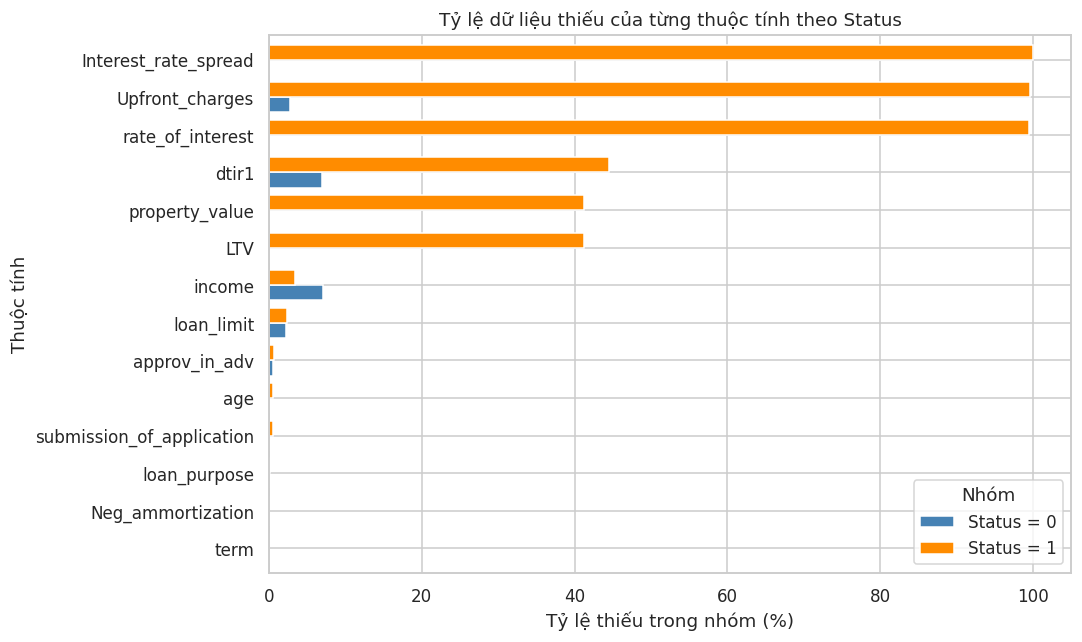

In [ ]:
# Biểu đồ so sánh tỷ lệ thiếu giữa hai nhóm Status
plot_data = missing_by_status[["% thiếu trong Status=0", "% thiếu trong Status=1"]].sort_values("% thiếu trong Status=1")

ax = plot_data.plot(kind="barh", figsize=(10, 6), color=["steelblue", "darkorange"], width=0.8)

# Thêm tiêu đề, nhãn trục và chú giải
ax.set_title("Tỷ lệ dữ liệu thiếu của từng thuộc tính theo Status")
ax.set_xlabel("Tỷ lệ thiếu trong nhóm (%)")
ax.set_ylabel("Thuộc tính")
ax.legend(["Status = 0", "Status = 1"], title="Nhóm", loc="lower right")
plt.tight_layout()
plt.show()

**Nhận xét:**

- `Interest_rate_spread` thiếu ở toàn bộ nhóm `Status = 1` (100%), trong khi nhóm `Status = 0` không thiếu giá trị nào. Tương tự, `rate_of_interest` và `Upfront_charges` cũng có tỷ lệ thiếu rất cao ở nhóm `Status = 1`, lần lượt là 99,45% và 99,58%.
- `property_value` và `LTV` đều thiếu 41,20% ở nhóm `Status = 1`, trong khi nhóm `Status = 0` chỉ có 2 dòng bị thiếu. `dtir1` cũng có sự chênh lệch đáng kể giữa hai nhóm (44,52% so với 6,97%).
- Ngược lại, `income` thiếu nhiều hơn ở nhóm `Status = 0` (7,06%) so với nhóm `Status = 1` (3,38%).
- Các cột còn lại có tỷ lệ thiếu tương đối thấp, phần lớn dưới 1%.

**Kết luận:** Dữ liệu thiếu có sự khác biệt rõ rệt giữa hai nhóm `Status`, đặc biệt ở các thuộc tính liên quan đến lãi suất và tài sản. Vì vậy, việc xóa các dòng bị thiếu hoặc tự động điền giá trị có thể làm sai lệch kết quả phân tích. Cần cân nhắc cách xử lý riêng cho từng thuộc tính.

In [ ]:
# Kiểm tra dữ liệu thiếu của Interest_rate_spread theo Status
missing_spread = pd.crosstab(
    df["Interest_rate_spread"].isnull(),
    df["Status"],
    margins=True,
    margins_name="Tổng"
)

# Đặt lại tên hàng và cột cho dễ đọc
missing_spread.index = ["Không thiếu", "Có thiếu", "Tổng"]
missing_spread.columns = ["Status = 0", "Status = 1", "Tổng"]
missing_spread.index.name = None
missing_spread.columns.name = None

display(missing_spread)

,Status = 0,Status = 1,Tổng
Không thiếu,112031,0,112031
Có thiếu,0,36639,36639
Tổng,112031,36639,148670


In [ ]:
# Thống kê các mẫu thiếu (missing pattern) kết hợp của các biến định giá, tài sản và dtir1
pattern_cols = ["rate_of_interest", "Interest_rate_spread", "Upfront_charges", "property_value", "dtir1"]
missing_pattern = (
    df[pattern_cols].isnull()
    .replace({True: "Thiếu", False: "Có"})
    .assign(Status=df["Status"])
    .groupby(pattern_cols)["Status"]
    .agg(["count", "mean"])
    .rename(columns={"count": "Số quan sát", "mean": "Tỷ lệ Status=1"})
    .sort_values("Số quan sát", ascending=False)
)
missing_pattern["Tỷ lệ Status=1"] = (missing_pattern["Tỷ lệ Status=1"] * 100).round(2)
display(missing_pattern.reset_index().head(8))

,rate_of_interest,Interest_rate_spread,Upfront_charges,property_value,dtir1,Số quan sát,Tỷ lệ Status=1
0,Có,Có,Có,Có,Có,101430,0.0
1,Thiếu,Thiếu,Thiếu,Có,Có,20329,100.0
2,Thiếu,Thiếu,Thiếu,Thiếu,Thiếu,15096,100.0
3,Có,Có,Có,Có,Thiếu,7445,0.0
4,Có,Có,Thiếu,Có,Có,2788,0.0
5,Thiếu,Thiếu,Thiếu,Có,Thiếu,1014,100.0
6,Có,Có,Thiếu,Có,Thiếu,366,0.0
7,Có,Thiếu,Có,Có,Thiếu,153,100.0


**Nhận xét:**

- `Interest_rate_spread` thiếu toàn bộ 36.639 dòng thuộc nhóm `Status = 1`, trong khi không có dòng nào thuộc nhóm `Status = 0` bị thiếu. Điều này cho thấy việc thiếu dữ liệu ở cột này có liên hệ trực tiếp với `Status`.
- Nếu sử dụng `dropna()` để xóa tất cả các dòng có giá trị thiếu, dữ liệu chỉ còn 98.187 dòng và tất cả đều thuộc nhóm `Status = 0`. Khi đó, không thể tiếp tục so sánh hai nhóm.
- Một số thuộc tính thường bị thiếu cùng nhau. Chẳng hạn, có 20.329 dòng thiếu đồng thời `rate_of_interest`, `Interest_rate_spread` và `Upfront_charges`, nhưng vẫn có thông tin `property_value` và `dtir1`.
- `LTV` và `dtir1` cũng thiếu nhiều ở nhóm `Status = 1`, nên các phép so sánh chỉ sử dụng giá trị có sẵn có thể không phản ánh đầy đủ đặc điểm của nhóm này.

**Kết luận:** Không nên xóa toàn bộ các dòng có `NaN` hoặc tự động điền giá trị thiếu. Đặc biệt, việc thiếu `Interest_rate_spread` có thể khiến mô hình dự đoán dựa vào dấu hiệu thiếu dữ liệu thay vì những đặc điểm thực sự của khoản vay.

## 2.3. Quyết định xử lý dữ liệu thiếu

Dựa trên kết quả kiểm tra ở mục 2.2, dữ liệu thiếu được xử lý như sau:

- **Các cột phân loại** (`loan_limit`, `approv_in_adv`, `loan_purpose`, `Neg_ammortization`): Điền `Unknown` để giữ lại các dòng dữ liệu và phân biệt những trường hợp thiếu thông tin.

- **`age` và `submission_of_application`**: Điền `Unknown` vì cả 200 dòng thiếu đều thuộc nhóm `Status = 1`. Riêng nhóm tuổi `Unknown` sẽ không được đưa vào kiểm định về tuổi.

- **`term`**: Điền Mode = 360 vì đây là giá trị xuất hiện nhiều nhất và chỉ có 41 dòng bị thiếu.

- **`income`**: Giữ nguyên `NaN` vì tỷ lệ thiếu khác nhau giữa hai nhóm `Status`. Việc điền Median có thể làm thay đổi phân phối dữ liệu.

- **`rate_of_interest`, `Interest_rate_spread` và `Upfront_charges`**: Giữ nguyên `NaN` vì dữ liệu thiếu tập trung chủ yếu ở nhóm `Status = 1`. Những cột này không được sử dụng để so sánh trực tiếp hai nhóm trong phân tích hiện tại.

- **`property_value`, `LTV` và `dtir1`**: Giữ nguyên `NaN` vì tỷ lệ thiếu khá cao, đặc biệt ở nhóm `Status = 1`. Khi phân tích, nhóm thiếu dữ liệu sẽ được xem xét riêng.

**Lựa chọn Median và Mean:** Với các biến có giá trị cực lớn như `income`, Median ít bị ảnh hưởng bởi ngoại lệ hơn Mean. Tuy nhiên, trong bài này, `income` được giữ nguyên các giá trị thiếu để tránh làm thay đổi kết quả so sánh giữa hai nhóm.

In [ ]:
# Kiểm tra số lượng từng giá trị trong cột loan_limit, bao gồm giá trị thiếu
display(df_clean["loan_limit"].value_counts(dropna=False).reset_index())

,loan_limit,count
0,cf,135348
1,ncf,9978
2,NaN,3344


In [ ]:
# Thay các giá trị thiếu trong loan_limit bằng Unknown
df_clean["loan_limit"] = df_clean["loan_limit"].fillna("Unknown")

# Kiểm tra các giá trị sau khi xử lý
display(df_clean["loan_limit"].value_counts(dropna=False).reset_index())

,loan_limit,count
0,cf,135348
1,ncf,9978
2,Unknown,3344


In [ ]:
# Kiểm tra số lượng từng giá trị trong cột approv_in_adv
display(df_clean["approv_in_adv"].value_counts(dropna=False).reset_index())

,approv_in_adv,count
0,nopre,124621
1,pre,23141
2,NaN,908


In [ ]:
# Thay giá trị thiếu trong approv_in_adv bằng Unknown
df_clean["approv_in_adv"] = df_clean["approv_in_adv"].fillna("Unknown")

# Kiểm tra kết quả sau khi xử lý
display(df_clean["approv_in_adv"].value_counts(dropna=False).reset_index())

,approv_in_adv,count
0,nopre,124621
1,pre,23141
2,Unknown,908


In [ ]:
# Kiểm tra số lượng từng giá trị trong cột loan_purpose
display(df_clean["loan_purpose"].value_counts(dropna=False).reset_index())

,loan_purpose,count
0,p3,55934
1,p4,54799
2,p1,34529
3,p2,3274
4,NaN,134


In [ ]:
# Thay giá trị thiếu trong loan_purpose bằng Unknown
df_clean["loan_purpose"] = df_clean["loan_purpose"].fillna("Unknown")

# Kiểm tra kết quả sau khi xử lý
display(df_clean["loan_purpose"].value_counts(dropna=False).reset_index())

,loan_purpose,count
0,p3,55934
1,p4,54799
2,p1,34529
3,p2,3274
4,Unknown,134


In [ ]:
# Kiểm tra các giá trị trong cột Neg_ammortization
display(df_clean["Neg_ammortization"].value_counts(dropna=False).reset_index())

,Neg_ammortization,count
0,not_neg,133420
1,neg_amm,15129
2,NaN,121


In [ ]:
# Thay giá trị thiếu trong Neg_ammortization bằng Unknown
df_clean["Neg_ammortization"] = df_clean["Neg_ammortization"].fillna("Unknown")

# Kiểm tra kết quả sau khi xử lý
display(df_clean["Neg_ammortization"].value_counts(dropna=False).reset_index())

,Neg_ammortization,count
0,not_neg,133420
1,neg_amm,15129
2,Unknown,121


In [ ]:
# Kiểm tra số lượng từng nhóm tuổi, bao gồm giá trị thiếu
display(df_clean["age"].value_counts(dropna=False).reset_index())

,age,count
0,45-54,34720
1,35-44,32818
2,55-64,32534
3,65-74,20744
4,25-34,19142
5,>74,7175
6,<25,1337
7,NaN,200


In [ ]:
# Thay các giá trị thiếu trong cột age bằng Unknown
df_clean["age"] = df_clean["age"].fillna("Unknown")

# Kiểm tra số lượng từng nhóm tuổi sau khi xử lý
display(df_clean["age"].value_counts(dropna=False).reset_index())

,age,count
0,45-54,34720
1,35-44,32818
2,55-64,32534
3,65-74,20744
4,25-34,19142
5,>74,7175
6,<25,1337
7,Unknown,200


In [ ]:
# Kiểm tra các giá trị trong cột submission_of_application
display(df_clean["submission_of_application"].value_counts(dropna=False).reset_index())

,submission_of_application,count
0,to_inst,95814
1,not_inst,52656
2,NaN,200


In [ ]:
# Thay giá trị thiếu trong submission_of_application bằng Unknown
df_clean["submission_of_application"] = df_clean["submission_of_application"].fillna("Unknown")

# Kiểm tra kết quả sau khi xử lý
display(df_clean["submission_of_application"].value_counts(dropna=False).reset_index())

,submission_of_application,count
0,to_inst,95814
1,not_inst,52656
2,Unknown,200


In [ ]:
# Kiểm tra thống kê mô tả của thời hạn khoản vay
display(df_clean["term"].describe().reset_index())

,index,term
0,count,148629.000000
1,mean,335.136582
2,std,58.409084
3,min,96.000000
4,25%,360.000000
5,50%,360.000000
6,75%,360.000000
7,max,360.000000


In [ ]:
# Đếm số lần xuất hiện của từng thời hạn khoản vay
display(df_clean["term"].value_counts(dropna=False).reset_index())

,term,count
0,360.0,121685
1,180.0,12981
2,240.0,5859
3,300.0,2822
4,324.0,2766
5,120.0,510
6,144.0,263
7,348.0,260
8,336.0,213
9,96.0,194


In [ ]:
# Điền giá trị thiếu của term bằng giá trị xuất hiện nhiều nhất
df_clean["term"] = df_clean["term"].fillna(
    df_clean["term"].mode()[0]
)

# Kiểm tra số lượng giá trị thiếu sau khi xử lý
print("Số giá trị term còn thiếu:", df_clean["term"].isnull().sum())

Số giá trị term còn thiếu: 0


### Xử lý giá trị thiếu trong cột `income`

Cột `income` có một số giá trị thiếu. Trước khi quyết định có nên điền Median hay không, ta sẽ so sánh dữ liệu trước và sau khi điền để xem phương pháp này ảnh hưởng như thế nào đến kết quả phân tích.

**Lưu ý:** Việc điền Median chỉ được thực hiện trên một Series riêng (`income_imputed`) để so sánh, không làm thay đổi `df_clean`.

In [ ]:
# Tính Mean, Median và Skewness của thu nhập
mean_income = df_clean["income"].mean()
median_income = df_clean["income"].median()

# Hiển thị kết quả
print("Mean:", mean_income)
print("Median:", median_income)
print("Skewness:", round(df_clean["income"].skew(), 2))

Mean: 6957.338876146789
Median: 5760.0
Skewness: 17.31


In [ ]:
# Thử điền Median vào một Series riêng, không thay đổi df_clean
income_imputed = df_clean["income"].fillna(median_income)

# So sánh thống kê trước và sau khi điền Median
impact_income = pd.DataFrame({
    "Trước": df_clean["income"].describe(),
    "Sau": income_imputed.describe()
})

display(impact_income.round(2).reset_index().rename(columns={"index": "Chỉ số"}))

# So sánh theo từng nhóm Status
impact_by_status = pd.DataFrame({
    "Median trước": df_clean.groupby("Status")["income"].median(),
    "Median sau": income_imputed.groupby(df_clean["Status"]).median(),
    "Std trước": df_clean.groupby("Status")["income"].std(),
    "Std sau": income_imputed.groupby(df_clean["Status"]).std()
})

display(impact_by_status.round(2).reset_index())

# So sánh effect size trước và sau khi điền Median
r_before = mann_whitney_report(
    df_clean.loc[status_0, "income"],
    df_clean.loc[status_1, "income"]
)["Rank-biserial r"]

r_after = mann_whitney_report(
    income_imputed[status_0],
    income_imputed[status_1]
)["Rank-biserial r"]

print(f"Rank-biserial r: {r_before:.4f} (trước) -> {r_after:.4f} (sau)")

,Chỉ số,Trước,Sau
0,count,139520.00,148670.00
1,mean,6957.34,6883.65
2,std,6496.59,6300.07
3,min,0.00,0.00
4,25%,3720.00,3840.00
5,50%,5760.00,5760.00
6,75%,8520.00,8280.00
7,max,578580.00,578580.00


,Status,Median trước,Median sau,Std trước,Std sau
0,0,6000.0,5760.0,6201.34,5989.81
1,1,4860.0,5040.0,7247.65,7124.56


Rank-biserial r: 0.1846 (trước) -> 0.1806 (sau)


**Nhận xét:** Sau khi điền 9.150 giá trị thiếu bằng Median (5.760), Mean và độ lệch chuẩn của thu nhập đều giảm. Median của từng nhóm `Status` cũng thay đổi, trong khi effect size giảm nhẹ từ 0,1846 xuống 0,1806.

Điều này cho thấy việc điền Median có thể làm thay đổi kết quả phân tích. Vì vậy, ta giữ nguyên các giá trị `NaN` trong cột `income` và chỉ sử dụng những giá trị có sẵn khi phân tích thu nhập.

In [ ]:
# Kiểm tra các quan sát có income = 0
income_zero = df_clean["income"] == 0

print("Số quan sát income = 0:", income_zero.sum())
print("Tỷ lệ Status = 1 trong nhóm income = 0: {:.2f}%".format(
    df_clean.loc[income_zero, "Status"].mean() * 100
))

# Kiểm tra phân bố credit_type trong nhóm income = 0
display(df_clean.loc[income_zero, "credit_type"].value_counts().reset_index())

Số quan sát income = 0: 1260
Tỷ lệ Status = 1 trong nhóm income = 0: 99.37%


,credit_type,count
0,EQUI,912
1,CIB,128
2,EXP,110
3,CRIF,110


**Nhận xét:** Có 1.260 khoản vay có `income = 0`, trong đó 99,37% thuộc nhóm `Status = 1`. Phần lớn các khoản vay này có `credit_type = EQUI` (912 khoản).

Chưa thể xác định thu nhập bằng 0 là giá trị thực tế hay cách ghi nhận dữ liệu thiếu. Vì vậy, ta giữ nguyên các quan sát này và sẽ kiểm tra xem việc loại chúng khỏi phân tích có làm thay đổi kết quả hay không ở mục 3.5.

## 2.4. Phát hiện và đánh giá giá trị ngoại lệ (Outliers)

Sử dụng thống kê mô tả, quy tắc IQR (1,5 × IQR) và biểu đồ hộp để phát hiện các giá trị ngoại lệ.

Tuy nhiên, không phải giá trị ngoại lệ nào cũng là dữ liệu sai. Đặc biệt, với những biến có phân phối lệch phải, các giá trị lớn vẫn có thể hợp lệ. Vì vậy, cần xem xét trước khi quyết định có loại bỏ hay không.

### 2.4.1. Số tiền vay (`loan_amount`)

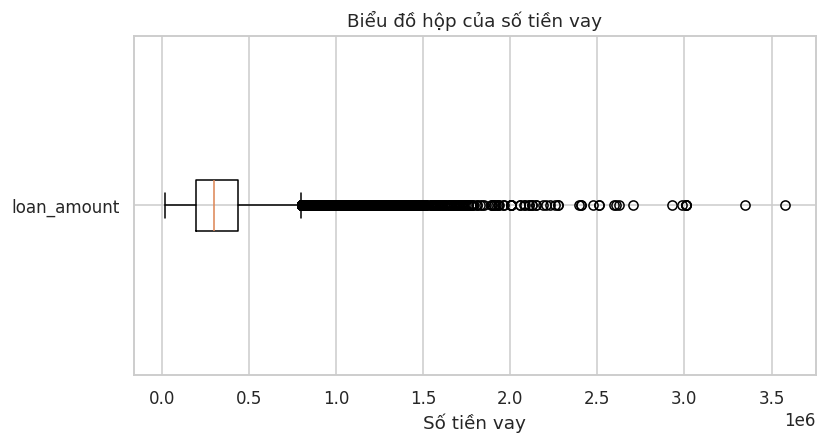

In [ ]:
# Vẽ biểu đồ hộp để kiểm tra ngoại lệ của loan_amount
plt.figure(figsize=(8, 4))
plt.boxplot(
    df_clean["loan_amount"].dropna(),
    vert=False,
    tick_labels=["loan_amount"]
)

plt.title("Biểu đồ hộp của số tiền vay")
plt.xlabel("Số tiền vay")

plt.show()

In [ ]:
# Tính Q1, Q3 và IQR của loan_amount
Q1 = df_clean["loan_amount"].quantile(0.25)
Q3 = df_clean["loan_amount"].quantile(0.75)
IQR = Q3 - Q1

# Xác định ngưỡng ngoại lệ theo quy tắc 1.5 × IQR
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Lọc các khoản vay nằm ngoài ngưỡng
outliers = df_clean[
    (df_clean["loan_amount"] < lower_bound) |
    (df_clean["loan_amount"] > upper_bound)
]

print("Ngưỡng dưới:", lower_bound)
print("Ngưỡng trên:", upper_bound)
print("Số lượng ngoại lệ:", len(outliers))

Ngưỡng dưới: -163500.0
Ngưỡng trên: 796500.0
Số lượng ngoại lệ: 1895


In [ ]:
# Hiển thị 10 khoản vay có giá trị lớn nhất
df_clean.nlargest(10, "loan_amount")[
    ["ID", "loan_amount", "property_value", "income", "LTV", "Status"]
]

,ID,loan_amount,property_value,income,LTV,Status
4321,29211,3576500,5208000.0,119340.0,68.673195,1
98146,123036,3346500,NaN,33840.0,NaN,1
3762,28652,3006500,5258000.0,50580.0,57.179536,0
54519,79409,3006500,5758000.0,66000.0,52.214311,0
86408,111298,3006500,3508000.0,43320.0,85.704105,1
121640,146530,3006500,NaN,114000.0,NaN,1
114333,139223,2986500,5508000.0,61500.0,54.221133,0
42200,67090,2926500,4878000.0,64020.0,59.993850,1
68421,93311,2706500,4508000.0,10800.0,60.037711,1
128145,153035,2626500,NaN,32940.0,NaN,1


**Nhận xét:** Có 1.895 khoản vay (1,27%) vượt ngưỡng trên 796.500, cho thấy phân phối số tiền vay có đuôi phải kéo dài.

Trong 10 khoản vay lớn nhất, những khoản có đủ thông tin tài sản đều có `LTV` khoảng 52-86%, cho thấy số tiền vay tương đối phù hợp với giá trị tài sản. Tuy nhiên, một số khoản còn thiếu thông tin nên chưa thể kết luận tất cả ngoại lệ đều hợp lệ.

**Quyết định:** Giữ nguyên các khoản vay này vì chưa có đủ bằng chứng cho thấy chúng là dữ liệu sai. Khi so sánh số tiền vay giữa các nhóm, sử dụng kiểm định Mann-Whitney để hạn chế ảnh hưởng của các giá trị quá lớn.

### 2.4.2. Thu nhập (`income`)

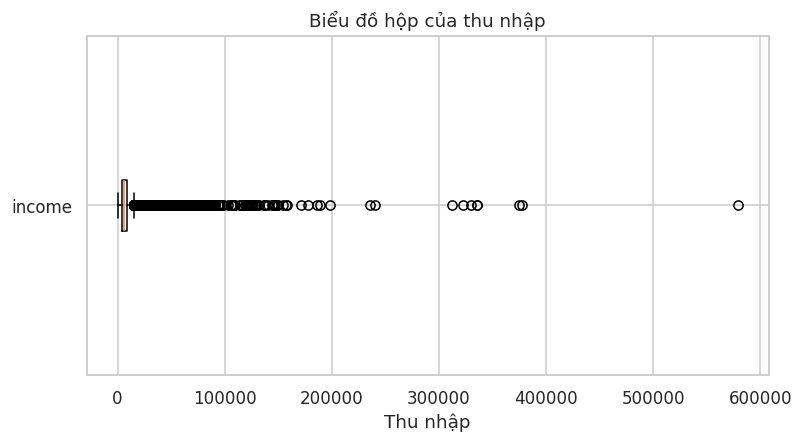

In [ ]:
# Vẽ biểu đồ hộp để kiểm tra ngoại lệ của income
plt.figure(figsize=(8, 4))

plt.boxplot(
    df_clean["income"].dropna(),
    vert=False,
    tick_labels=["income"]
)

plt.title("Biểu đồ hộp của thu nhập")
plt.xlabel("Thu nhập")

plt.show()

In [ ]:
# Tính Q1, Q3 và IQR của income
Q1_income = df_clean["income"].quantile(0.25)
Q3_income = df_clean["income"].quantile(0.75)
IQR_income = Q3_income - Q1_income

# Xác định ngưỡng ngoại lệ theo quy tắc 1.5 × IQR
lower_income = Q1_income - 1.5 * IQR_income
upper_income = Q3_income + 1.5 * IQR_income

# Lọc các quan sát nằm ngoài ngưỡng
outliers_income = df_clean[
    (df_clean["income"] < lower_income) |
    (df_clean["income"] > upper_income)
]

print("Ngưỡng dưới:", lower_income)
print("Ngưỡng trên:", upper_income)
print("Số lượng ngoại lệ:", len(outliers_income))

Ngưỡng dưới: -3480.0
Ngưỡng trên: 15720.0
Số lượng ngoại lệ: 6546


**Nhận xét:** Có 6.546 giá trị thu nhập (4,69% số quan sát có thu nhập) vượt ngưỡng trên 15.720. Giá trị lớn nhất là 578.580, cao gấp khoảng 100 lần Median (5.760), cho thấy phân phối thu nhập lệch phải rất mạnh.

**Quyết định:** Giữ nguyên các giá trị ngoại lệ vì chưa có đủ bằng chứng cho thấy chúng là dữ liệu sai. Khi phân tích, ưu tiên sử dụng Median và kiểm định Mann–Whitney để hạn chế ảnh hưởng của các giá trị quá lớn.

### 2.4.3. Giá trị tài sản (`property_value`), LTV và DTI

In [ ]:
# Tổng hợp giá trị ngoại lệ theo quy tắc IQR
outlier_cols = ["loan_amount", "income", "property_value", "LTV", "dtir1"]
outlier_rows = []

for col in outlier_cols:
    values = df_clean[col].dropna()
    q1, q3, low, high = iqr_bounds(values)

    outlier_rows.append({
        "Thuộc tính": col,
        "n": len(values),
        "Q1": q1,
        "Q3": q3,
        "Ngưỡng dưới": low,
        "Ngưỡng trên": high,
        "Dưới": (values < low).sum(),
        "Trên": (values > high).sum(),
        "Ngoại lệ (%)": round(((values < low) | (values > high)).mean() * 100, 2),
        "Min": values.min(),
        "Max": values.max(),
        "Skewness": round(values.skew(), 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).round(2)
display(outlier_summary)

,Thuộc tính,n,Q1,Q3,Ngưỡng dưới,Ngưỡng trên,Dưới,Trên,Ngoại lệ (%),Min,Max,Skewness
0,loan_amount,148670,196500.00,436500.00,-163500.00,796500.00,0,1895,1.27,16500.00,3576500.00,1.67
1,income,139520,3720.00,8520.00,-3480.00,15720.00,0,6546,4.69,0.00,578580.00,17.31
2,property_value,133572,268000.00,628000.00,-272000.00,1168000.00,0,5266,3.94,8000.00,16508000.00,4.59
3,LTV,133572,60.47,86.18,21.91,124.75,1762,120,1.41,0.97,7831.25,120.62
4,dtir1,124549,31.00,45.00,10.00,66.00,2013,0,1.62,5.00,61.00,-0.55


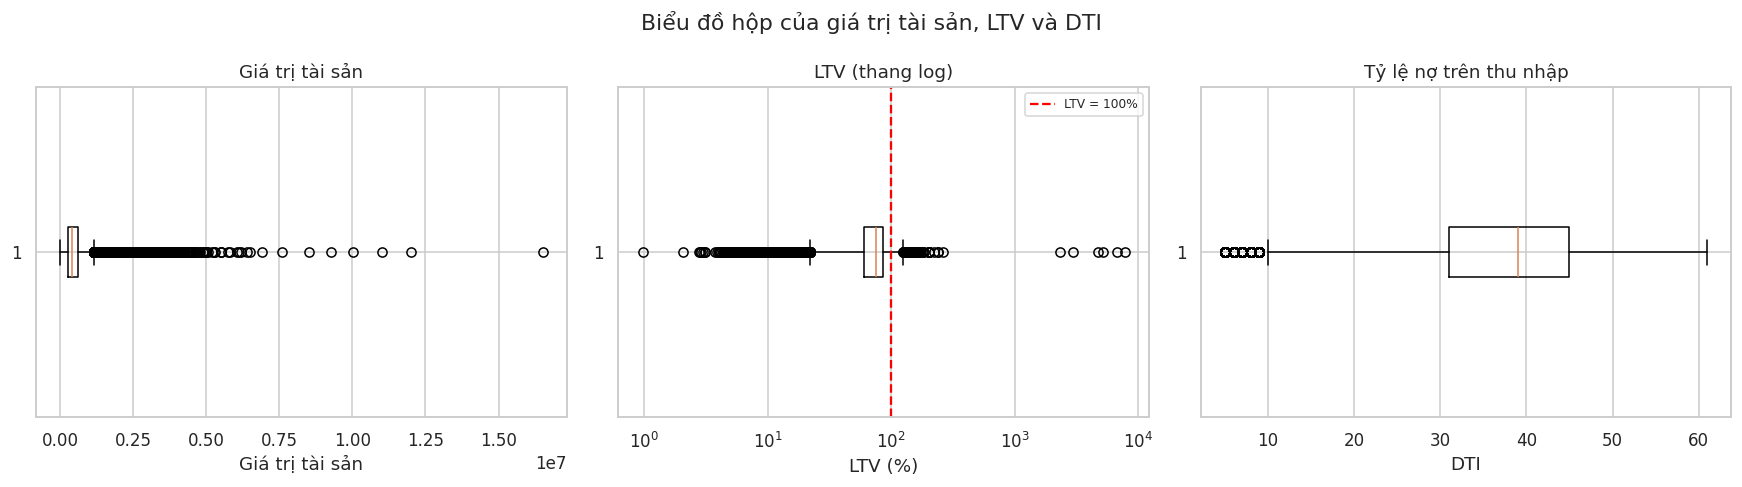

In [ ]:
# Vẽ biểu đồ hộp cho property_value, LTV và dtir1
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].boxplot(df_clean["property_value"].dropna(), vert=False)
axes[0].set_title("Giá trị tài sản")
axes[0].set_xlabel("Giá trị tài sản")

axes[1].boxplot(df_clean["LTV"].dropna(), vert=False)
axes[1].set_xscale("log")
axes[1].axvline(100, color="red", linestyle="--", label="LTV = 100%")
axes[1].set_title("LTV (thang log)")
axes[1].set_xlabel("LTV (%)")
axes[1].legend(fontsize=8)

axes[2].boxplot(df_clean["dtir1"].dropna(), vert=False)
axes[2].set_title("Tỷ lệ nợ trên thu nhập")
axes[2].set_xlabel("DTI")

fig.suptitle("Biểu đồ hộp của giá trị tài sản, LTV và DTI")
plt.tight_layout()
plt.show()

**Nhận xét:**

- `property_value`: Có 5.266 giá trị (3,94%) vượt ngưỡng trên IQR. Phân phối lệch phải, tương tự số tiền vay. Chưa có đủ bằng chứng để xem các giá trị lớn này là dữ liệu sai nên tạm thời giữ nguyên.
- `dtir1`: Có 2.013 giá trị (1,62%) nằm dưới ngưỡng IQR. Các giá trị này vẫn nằm trong phạm vi dữ liệu từ 5 đến 61 nên được giữ lại.
- `LTV`: Có 1.882 giá trị ngoại lệ (1,41%). Đặc biệt, giá trị lớn nhất lên đến 7.831,25%, cao bất thường và cần được kiểm tra kỹ hơn ở phần tiếp theo.

### 2.4.4. Điều tra các giá trị LTV cực lớn

In [ ]:
# Kiểm tra các khoản vay vượt từng ngưỡng LTV
ltv_threshold_rows = []

for threshold in [100, 120, 150, 200, 1000]:
    mask = df_clean["LTV"] > threshold
    ltv_threshold_rows.append({
        "Ngưỡng": f"LTV > {threshold}%",
        "Số khoản vay": mask.sum(),
        "Tỷ lệ Status = 1 (%)": round(df_clean.loc[mask, "Status"].mean() * 100, 2)
    })

display(pd.DataFrame(ltv_threshold_rows).set_index("Ngưỡng"))

# Hiển thị 10 khoản vay có LTV lớn nhất
top_ltv = df_clean.nlargest(10, "LTV")[
    ["ID", "loan_amount", "property_value", "LTV", "income", "Status"]
].copy()

top_ltv["LTV"] = top_ltv["LTV"].round(2)
display(top_ltv.reset_index(drop=True))

,Số khoản vay,Tỷ lệ Status = 1 (%)
Ngưỡng,,
LTV > 100%,1799,65.09
LTV > 120%,193,96.37
LTV > 150%,33,81.82
LTV > 200%,17,64.71
LTV > 1000%,6,16.67


,ID,loan_amount,property_value,LTV,income,Status
0,41841,626500,8000.0,7831.25,NaN,0
1,80176,536500,8000.0,6706.25,NaN,0
2,72697,416500,8000.0,5206.25,NaN,0
3,90128,376500,8000.0,4706.25,NaN,0
4,71177,236500,8000.0,2956.25,NaN,1
5,148233,186500,8000.0,2331.25,NaN,0
6,68238,126500,48000.0,263.54,3360.0,1
7,52363,66500,28000.0,237.50,2100.0,1
8,55727,66500,28000.0,237.50,1560.0,1
9,161044,546500,248000.0,220.36,NaN,0


In [ ]:
# Đánh dấu các khoản vay có LTV bất thường
ltv_suspect = df_clean["LTV"] > 1000

print("Số khoản vay nghi ngờ:", ltv_suspect.sum())
print("Giá trị tài sản của nhóm nghi ngờ:",
      df_clean.loc[ltv_suspect, "property_value"].unique())
print("LTV lớn nhất ngoài nhóm:",
      round(df_clean.loc[~ltv_suspect, "LTV"].max(), 2))

# So sánh thống kê khi giữ và loại 6 dòng nghi ngờ
ltv_sensitivity = pd.DataFrame({
    "Giữ toàn bộ": df_clean["LTV"].describe(),
    "Loại 6 dòng": df_clean.loc[~ltv_suspect, "LTV"].describe()
})

ltv_sensitivity.loc["skewness"] = [
    df_clean["LTV"].skew(),
    df_clean.loc[~ltv_suspect, "LTV"].skew()
]

display(
    ltv_sensitivity.round(2)
    .reset_index()
    .rename(columns={"index": "Chỉ số"})
)

Số khoản vay nghi ngờ: 6
Giá trị tài sản của nhóm nghi ngờ: [8000.]
LTV lớn nhất ngoài nhóm: 263.54


,Chỉ số,Giữ toàn bộ,Loại 6 dòng
0,count,133572.00,133566.00
1,mean,72.75,72.53
2,std,39.97,18.94
3,min,0.97,0.97
4,25%,60.47,60.47
5,50%,75.14,75.14
6,75%,86.18,86.18
7,max,7831.25,263.54
8,skewness,120.62,-0.63


### Nhận xét và quyết định xử lý LTV

Có 6 khoản vay có LTV đặc biệt cao, từ 2.331% đến 7.831%. Cả 6 đều có `property_value = 8.000`, trong khi số tiền vay lớn hơn rất nhiều. Giá trị LTV cao nhất còn lại chỉ là 263,54%, cho thấy 6 khoản vay này khác biệt rõ rệt so với phần còn lại của dữ liệu.

Khi loại tạm thời 6 dòng này để kiểm tra, độ lệch chuẩn của LTV giảm từ 39,97 xuống 18,94 và Skewness giảm từ 120,62 xuống −0,63. Trong khi đó, Mean chỉ thay đổi nhẹ và Median gần như không đổi.

Điều này cho thấy 6 giá trị cực lớn ảnh hưởng mạnh đến phân phối LTV, đặc biệt là độ lệch chuẩn và Skewness. Tuy nhiên, chưa thể xác định đây có phải lỗi dữ liệu hay không.

**Quyết định:** Giữ nguyên dữ liệu và đánh dấu 6 khoản vay nghi ngờ để theo dõi. Trong các phân tích tiếp theo, ưu tiên sử dụng nhóm LTV, kiểm định Mann–Whitney và hệ số tương quan Spearman để hạn chế ảnh hưởng của các giá trị cực lớn.

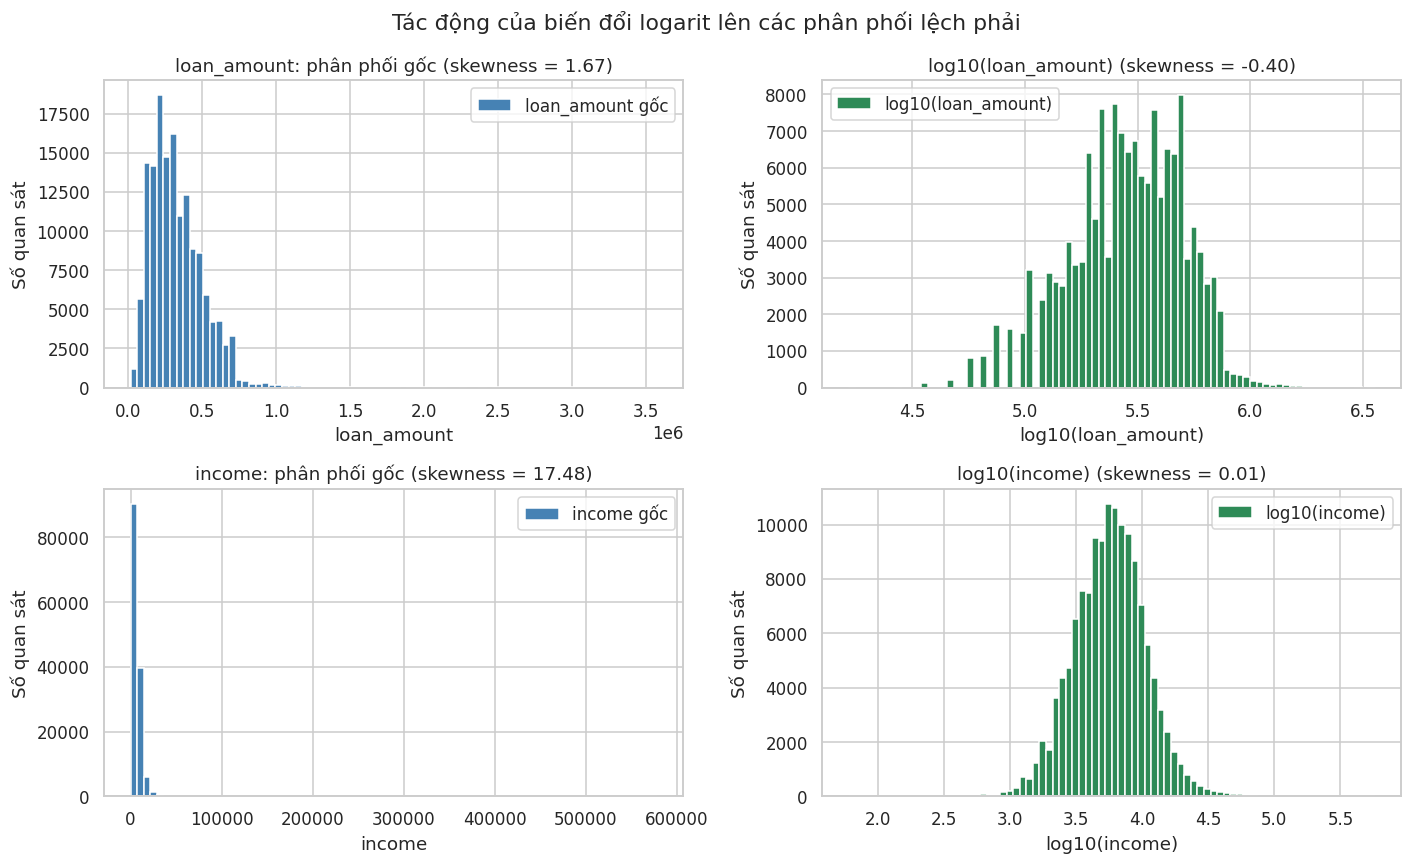

In [ ]:
# So sánh phân phối gốc và phân phối sau biến đổi log10 (chỉ phục vụ trực quan hóa)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for row, col in enumerate(["loan_amount", "income"]):
    values = df_clean[col].dropna()
    # Chỉ lấy giá trị dương để áp dụng log10
    values = values[values > 0]

    axes[row, 0].hist(values, bins=80, color="steelblue", label=f"{col} gốc")
    axes[row, 0].set_title(f"{col}: phân phối gốc (skewness = {values.skew():.2f})")
    axes[row, 0].set_xlabel(col)
    axes[row, 0].set_ylabel("Số quan sát")
    axes[row, 0].legend()

    log_values = np.log10(values)
    axes[row, 1].hist(log_values, bins=80, color="seagreen", label=f"log10({col})")
    axes[row, 1].set_title(f"log10({col}) (skewness = {log_values.skew():.2f})")
    axes[row, 1].set_xlabel(f"log10({col})")
    axes[row, 1].set_ylabel("Số quan sát")
    axes[row, 1].legend()

fig.suptitle("Tác động của biến đổi logarit lên các phân phối lệch phải")
plt.tight_layout()
plt.show()

**Nhận xét:** Sau khi biến đổi log10, phân phối của `loan_amount` và `income` trở nên cân đối hơn. Skewness của `loan_amount` giảm từ 1,67 xuống −0,40, còn `income` giảm từ 17,48 xuống 0,01.

Biến đổi log giúp quan sát dữ liệu rõ hơn khi có nhiều giá trị lớn. Tuy nhiên, các cột gốc vẫn được giữ nguyên để dễ diễn giải kết quả phân tích.

**Lưu ý:** Phép biến đổi log10 chỉ áp dụng cho các giá trị lớn hơn 0. Vì vậy, 1.260 quan sát có `income = 0` không xuất hiện trong biểu đồ này.

## 2.5. Encoding và Scaling

Sau khi làm sạch dữ liệu, nhóm thực hiện Encoding và Scaling trên một bản sao `df_transformed` để minh họa quá trình chuẩn bị dữ liệu cho mô hình dự đoán.

- **Encoding:** Sử dụng One-hot Encoding cho các biến phân loại vì chúng có ít nhóm và phần lớn không có thứ tự.
- **Scaling:** Sử dụng RobustScaler cho các biến tài chính có nhiều giá trị ngoại lệ và StandardScaler cho `Credit_Score` và `dtir1`.

Các phép biến đổi không làm thay đổi dữ liệu gốc `df` hoặc dữ liệu đã làm sạch `df_clean`. Giai đoạn 3 vẫn sử dụng `df_clean` để các kết quả thống kê giữ nguyên.

**Note:** Đây chỉ là bước minh họa tiền xử lý

In [ ]:
# Đếm số nhóm của từng biến phân loại sau khi làm sạch
category_cardinality = (
    df_clean.select_dtypes(include="object")
    .nunique()
    .sort_values(ascending=False)
    .rename("Số nhóm")
    .reset_index()
    .rename(columns={"index": "Thuộc tính"})
)

display(category_cardinality)

,Thuộc tính,Số nhóm
0,age,8
1,loan_purpose,5
2,Gender,4
3,credit_type,4
4,total_units,4
5,Region,4
6,loan_type,3
7,loan_limit,3
8,approv_in_adv,3
9,Neg_ammortization,3


**Nhận xét:** Dữ liệu có 21 biến phân loại, trong đó `age` có nhiều nhóm nhất (8 nhóm, bao gồm `Unknown`). Các biến còn lại có từ 2 đến 5 nhóm. Vì số nhóm không quá lớn, One-hot Encoding là lựa chọn phù hợp để chuyển các biến phân loại thành dữ liệu số.

In [ ]:
# Tạo bản sao để thực hiện Encoding và Scaling
df_transformed = df_clean.copy()

# Lấy danh sách các biến phân loại
categorical_cols = df_transformed.select_dtypes(
    include="object"
).columns

# Thực hiện One-hot Encoding
df_transformed = pd.get_dummies(
    df_transformed,
    columns=categorical_cols,
    dtype=int
)

# Kiểm tra số cột trước và sau Encoding
print("Số cột trước Encoding:", df_clean.shape[1])
print("Số cột sau Encoding:", df_transformed.shape[1])

# Hiển thị một số cột đã mã hóa
encoded_cols = df_transformed.columns.difference(df_clean.columns)

display(df_transformed[encoded_cols[:10]].head())

Số cột trước Encoding: 34
Số cột sau Encoding: 78


,Credit_Worthiness_l1,Credit_Worthiness_l2,Gender_Female,Gender_Joint,Gender_Male,Gender_Sex Not Available,Neg_ammortization_Unknown,Neg_ammortization_neg_amm,Neg_ammortization_not_neg,Region_Central
0,1,0,0,0,0,1,0,0,1,0
1,1,0,0,0,1,0,0,0,1,0
2,1,0,0,0,1,0,0,1,0,0
3,1,0,0,0,1,0,0,0,1,0
4,1,0,0,1,0,0,0,0,1,0


In [ ]:

# Chọn các biến cần chuẩn hóa
robust_cols = ["loan_amount", "income", "property_value", "LTV"]
standard_cols = ["Credit_Score", "dtir1"]

# Thực hiện RobustScaler cho các biến có nhiều ngoại lệ
robust_scaler = RobustScaler()
df_transformed[robust_cols] = robust_scaler.fit_transform(
    df_transformed[robust_cols]
)

# Thực hiện StandardScaler cho các biến còn lại
standard_scaler = StandardScaler()
df_transformed[standard_cols] = standard_scaler.fit_transform(
    df_transformed[standard_cols]
)

# So sánh kết quả trước và sau Scaling
print("Trước Scaling:")
display(df_clean[robust_cols + standard_cols].head())

print("Sau Scaling:")
display(df_transformed[robust_cols + standard_cols].head())

Trước Scaling:


,loan_amount,income,property_value,LTV,Credit_Score,dtir1
0,116500,1740.0,118000.0,98.728814,758,45.0
1,206500,4980.0,NaN,NaN,552,NaN
2,406500,9480.0,508000.0,80.019685,834,46.0
3,456500,11880.0,658000.0,69.376900,587,42.0
4,696500,10440.0,758000.0,91.886544,602,39.0


Sau Scaling:


,loan_amount,income,property_value,LTV,Credit_Score,dtir1
0,-0.750000,-0.8375,-0.833333,0.917680,0.502357,0.689123
1,-0.375000,-0.1625,NaN,NaN,-1.275413,NaN
2,0.458333,0.7750,0.250000,0.189963,1.158234,0.783951
3,0.666667,1.2750,0.666667,-0.224003,-0.973365,0.404638
4,1.666667,0.9750,0.944444,0.651540,-0.843916,0.120154


**Nhận xét:**

- **Encoding:** Sau khi áp dụng One-hot Encoding cho 21 biến phân loại, số cột tăng từ **34 lên 78**. Các nhóm được chuyển thành các cột có giá trị 0 hoặc 1, giúp dữ liệu phù hợp hơn với các thuật toán yêu cầu đầu vào dạng số.
- **Scaling:** RobustScaler được áp dụng cho `loan_amount`, `income`, `property_value` và `LTV` vì các biến này có nhiều giá trị ngoại lệ. StandardScaler được sử dụng cho `Credit_Score` và `dtir1` để chuẩn hóa thang đo.
- **Kết quả:** Các giá trị số đã được biến đổi nhưng vẫn giữ nguyên thứ tự tương đối. Những giá trị `NaN` chưa được thay thế, và toàn bộ quá trình chỉ thực hiện trên bản sao `df_transformed`.

## 2.6. Kiểm tra kết quả làm sạch

In [ ]:
# Kiểm tra các cột vẫn còn giá trị thiếu sau khi làm sạch
missing_remaining = df_clean.isnull().sum()
missing_remaining = missing_remaining[missing_remaining > 0]

display(
    missing_remaining.rename("Số lượng thiếu")
    .reset_index()
    .rename(columns={"index": "Thuộc tính"})
)

,Thuộc tính,Số lượng thiếu
0,rate_of_interest,36439
1,Interest_rate_spread,36639
2,Upfront_charges,39642
3,property_value,15098
4,income,9150
5,LTV,15098
6,dtir1,24121


In [ ]:
# So sánh dữ liệu thiếu trước và sau khi làm sạch
comparison = pd.DataFrame({
    "Trước xử lý": df.isnull().sum(),
    "Sau xử lý": df_clean.isnull().sum()
})

# Chỉ lấy các cột ban đầu có dữ liệu thiếu
comparison = comparison[comparison["Trước xử lý"] > 0].copy()

# Ghi nhận cách xử lý
comparison["Quyết định"] = np.where(
    comparison["Sau xử lý"] == 0,
    "Đã điền",
    "Giữ NaN"
)

display(comparison.reset_index().rename(columns={"index": "Thuộc tính"}))

,Thuộc tính,Trước xử lý,Sau xử lý,Quyết định
0,loan_limit,3344,0,Đã điền
1,approv_in_adv,908,0,Đã điền
2,loan_purpose,134,0,Đã điền
3,rate_of_interest,36439,36439,Giữ NaN
4,Interest_rate_spread,36639,36639,Giữ NaN
5,Upfront_charges,39642,39642,Giữ NaN
6,term,41,0,Đã điền
7,Neg_ammortization,121,0,Đã điền
8,property_value,15098,15098,Giữ NaN
9,income,9150,9150,Giữ NaN


In [ ]:
# So sánh kích thước dữ liệu trước và sau khi làm sạch
print("Dữ liệu gốc:", df.shape)
print("Dữ liệu sau xử lý:", df_clean.shape)

Dữ liệu gốc: (148670, 34)
Dữ liệu sau xử lý: (148670, 34)


In [ ]:
# Kiểm tra các giá trị đã chuẩn hóa của Security_Type và Region
print("Security_Type:")
print(df_clean["Security_Type"].unique())

print("\nRegion:")
print(df_clean["Region"].unique())

Security_Type:
['direct' 'Indirect']

Region:
['South' 'North' 'Central' 'North-East']


In [ ]:
# Kiểm tra bản ghi và ID trùng lặp sau khi làm sạch
print("Số bản ghi trùng lặp:", df_clean.duplicated().sum())
print("Số ID trùng lặp:", df_clean["ID"].duplicated().sum())

# Kiểm tra hai giá trị ban đầu vẫn tồn tại trong df
print(
    "Dữ liệu gốc vẫn chứa 'Indriect' và 'south':",
    (df["Security_Type"] == "Indriect").any()
    and (df["Region"] == "south").any()
)

Số bản ghi trùng lặp: 0
Số ID trùng lặp: 0
Dữ liệu gốc vẫn chứa 'Indriect' và 'south': True


**Tổng kết Giai đoạn 2.** Sau khi làm sạch, `df_clean` vẫn giữ nguyên **148.670 dòng và 34 cột**. Hai lỗi định dạng đã được sửa; 7 cột được điền giá trị thiếu bằng `Unknown` hoặc Mode, trong khi 7 cột còn lại được giữ `NaN` có chủ đích do dữ liệu thiếu có liên quan đến `Status`.

Không phát hiện bản ghi trùng lặp. Sáu dòng có LTV bất thường được xác định bằng biến `ltv_suspect` và giữ lại để tránh loại bỏ dữ liệu khi chưa xác minh được lỗi.

# Giai đoạn 3. Phân tích, kiểm định giả thuyết và trực quan hóa

## 3.0. Phương pháp phân tích

Các kiểm định được lựa chọn dựa trên loại biến và đặc điểm phân phối đã xem xét ở Giai đoạn 2.

| Loại biến so với `Status` | Kiểm định | Effect size |
|---|---|---|
| Biến phân loại | Chi-square | Cramér's V |
| Biến số hoặc thứ bậc | Mann–Whitney U (hai phía) | Rank-biserial r |

**Chi-square:** Dùng để kiểm tra mối liên hệ giữa hai biến phân loại. Cần chú ý tính độc lập của các quan sát và tần số kỳ vọng trong bảng. Với bảng 2×2, `chi2_contingency` mặc định áp dụng hiệu chỉnh Yates.

**Mann–Whitney U:** Dùng để so sánh phân phối thứ hạng giữa hai nhóm `Status`. Kiểm định không yêu cầu dữ liệu có phân phối chuẩn, phù hợp với các biến tài chính có phân phối lệch và nhiều giá trị ngoại lệ. Tuy nhiên, kết quả không tự động có nghĩa là trung vị của hai nhóm khác nhau.

**Đánh giá kết quả:** Ngoài p-value, bài phân tích sử dụng effect size để xem xét mức độ liên hệ hoặc khác biệt. Với cỡ mẫu lớn, những khác biệt nhỏ cũng có thể đạt ý nghĩa thống kê, nên không chỉ dựa vào p-value để đưa ra nhận xét.

Do thực hiện nhiều kiểm định, bảng tổng hợp ở mục 3.12 sẽ áp dụng hiệu chỉnh Bonferroni.

**Giới hạn:** Dữ liệu mang tính quan sát, vì vậy các kết quả chỉ phản ánh mối liên hệ, không chứng minh quan hệ nhân quả.

**Xử lý dữ liệu thiếu:** Nhóm `Unknown` của `age` được loại khỏi kiểm định tuổi vì cả 200 dòng đều có `Status = 1`. Với `income`, `LTV` và `dtir1`, kiểm định Mann–Whitney chỉ sử dụng các dòng có giá trị tương ứng. Riêng `LTV` và `dtir1`, tình trạng thiếu dữ liệu cũng được phân tích riêng để đánh giá khả năng ảnh hưởng đến kết quả.

## 3.0.1. Phân phối biến mục tiêu `Status`

In [ ]:
# Kiểm tra số lượng quan sát thuộc từng nhóm Status
display(df_clean["Status"].value_counts().reset_index())

,Status,count
0,0,112031
1,1,36639


In [ ]:
# Tính tỷ lệ phần trăm của từng nhóm Status
status_percentage = df_clean["Status"].value_counts(normalize=True) * 100

# Lưu tỷ lệ Status = 1 làm mốc so sánh cho các biểu đồ
OVERALL_RATE = status_percentage.loc[1]

# Hiển thị kết quả
display(
    status_percentage.round(2)
    .rename("Tỷ lệ (%)")
    .rename_axis("Status")
    .reset_index()
)

,Status,Tỷ lệ (%)
0,0,75.36
1,1,24.64


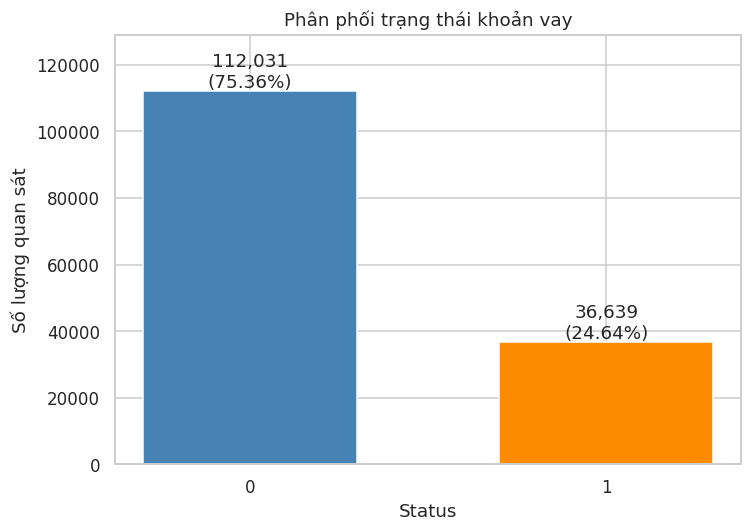

In [ ]:
# Đếm số lượng quan sát của từng nhóm Status
status_counts = df_clean["Status"].value_counts().sort_index()

# Vẽ biểu đồ cột
plt.figure(figsize=(7, 5))
bars = plt.bar(
    status_counts.index.astype(str),
    status_counts.values,
    color=["steelblue", "darkorange"],
    width=0.6
)

# Hiển thị số lượng và tỷ lệ trên từng cột
for bar, n, pct in zip(
    bars,
    status_counts.values,
    status_percentage.sort_index().values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        n,
        f"{n:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.title("Phân phối trạng thái khoản vay")
plt.xlabel("Status")
plt.ylabel("Số lượng quan sát")
plt.ylim(0, status_counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Nhận xét:** `Status = 0` chiếm **75,36%** (112.031 khoản vay), trong khi `Status = 1` chiếm **24,64%** (36.639 khoản vay), tương đương tỷ lệ khoảng 3:1. Dữ liệu có sự mất cân bằng giữa hai nhóm.

Trong các phân tích tiếp theo, tỷ lệ chung **24,64%** của `Status = 1` sẽ được sử dụng làm mốc tham chiếu để so sánh tỷ lệ giữa các nhóm khoản vay.

## 3.1. Nhóm tuổi và `Status`

- **Giả thuyết H₀:** Nhóm tuổi và `Status` độc lập với nhau.
- **Giả thuyết H₁:** Có mối liên hệ giữa nhóm tuổi và `Status`.
- **Lý do chọn biến:** Tuổi là một đặc điểm nhân khẩu học có thể liên quan đến tình trạng khoản vay. Phân tích này nhằm tìm hiểu sự khác biệt giữa các nhóm tuổi, không nhằm đề xuất sử dụng tuổi làm tiêu chí xét duyệt khoản vay.

In [ ]:
# Sắp xếp các nhóm tuổi theo thứ tự
age_order = ["<25", "25-34", "35-44", "45-54",
             "55-64", "65-74", ">74", "Unknown"]

# Đếm số lượng quan sát theo nhóm tuổi và Status
age_status = pd.crosstab(
    df_clean["age"],
    df_clean["Status"]
).reindex(age_order)

# Hiển thị bảng
display(age_status.rename_axis("Nhóm tuổi").reset_index())

Status,Nhóm tuổi,0,1
0,<25,950,387
1,25-34,14894,4248
2,35-44,25509,7309
3,45-54,26371,8349
4,55-64,24112,8422
5,65-74,15173,5571
6,>74,5022,2153
7,Unknown,0,200


In [ ]:
# Tính tỷ lệ phần trăm Status trong từng nhóm tuổi
age_status_percentage = age_status.div(
    age_status.sum(axis=1), axis=0
) * 100

# Hiển thị kết quả theo thứ tự nhóm tuổi
display(
    age_status_percentage.reindex(age_order)
    .round(2)
    .rename_axis("Nhóm tuổi")
    .reset_index()
)

Status,Nhóm tuổi,0,1
0,<25,71.05,28.95
1,25-34,77.81,22.19
2,35-44,77.73,22.27
3,45-54,75.95,24.05
4,55-64,74.11,25.89
5,65-74,73.14,26.86
6,>74,69.99,30.01
7,Unknown,0.00,100.00


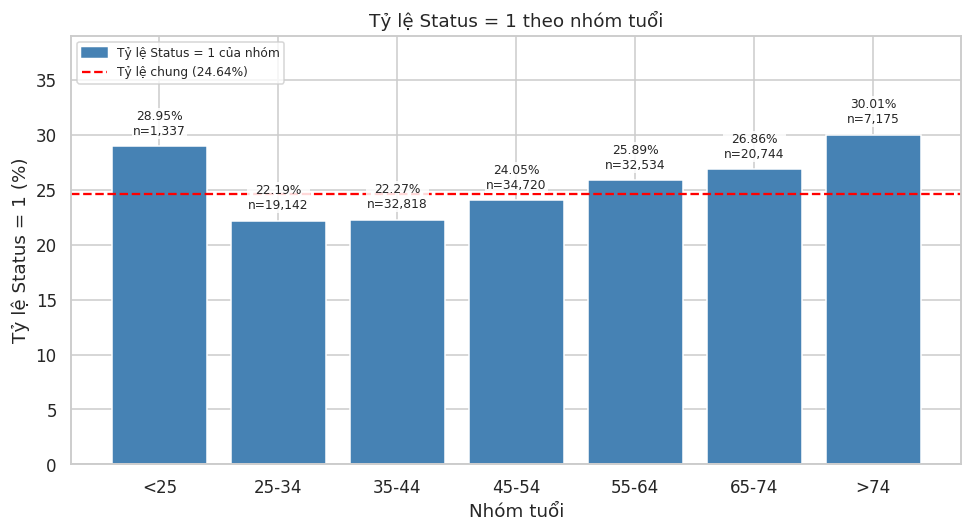

In [ ]:
# Lấy các nhóm tuổi đã biết, loại Unknown
age_groups = [age for age in age_order if age != "Unknown"]

# Lấy tỷ lệ Status = 1 và số quan sát theo nhóm tuổi
age_rate = age_status_percentage.loc[age_groups, 1]
age_n = age_status.loc[age_groups].sum(axis=1)

# Vẽ biểu đồ tỷ lệ Status = 1 theo nhóm tuổi
plot_status_rate(
    age_rate, age_n,
    "Tỷ lệ Status = 1 theo nhóm tuổi",
    "Nhóm tuổi", OVERALL_RATE
)

plt.tight_layout()
plt.show()

In [ ]:
# Loại nhóm Unknown khỏi kiểm định
age_table = age_status.drop(index="Unknown")

# Kiểm định Chi-square
chi2, p_value, dof, expected = chi2_contingency(age_table)

# Tính Cramér's V
n = age_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(age_table.shape) - 1)))

# Hiển thị kết quả
print(f"Chi-square: {chi2:.4f}")
print(f"Bậc tự do: {dof}")
print(f"P-value: {p_value:.4g}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Tần số kỳ vọng nhỏ nhất: {expected.min():.1f}")

Chi-square: 374.5016
Bậc tự do: 6
P-value: 8.442e-78
Cramér's V: 0.0502
Tần số kỳ vọng nhỏ nhất: 328.1


In [ ]:
# Tính Cramér's V để đánh giá mức độ liên hệ
n = age_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(age_table.shape) - 1)))

print(f"Cramér's V: {cramers_v:.4f} ({label_effect(cramers_v)})")

Cramér's V: 0.0502 (Không đáng kể)


**Nhận xét:**

- **Phân phối:** Tỷ lệ `Status = 1` tăng dần từ **22,19%** ở nhóm 25–34 tuổi lên **30,01%** ở nhóm trên 74 tuổi, chênh lệch 7,82 điểm phần trăm. Riêng nhóm dưới 25 tuổi có tỷ lệ khá cao (28,95%), nhưng số quan sát ít hơn các nhóm còn lại (1.337).
- **Kiểm định:** Chi-square cho kết quả χ² = 374,50, p < 0,001, nên bác bỏ H₀. Tần số kỳ vọng nhỏ nhất là 328,1, đáp ứng điều kiện áp dụng kiểm định.
- **Mức độ liên hệ:** Cramér's V = **0,0502**, cho thấy mối liên hệ giữa nhóm tuổi và `Status` rất yếu. Mặc dù có ý nghĩa thống kê, mức độ liên hệ thực tế là nhỏ.
- **Giới hạn:** Kết quả chưa xét đến ảnh hưởng của các yếu tố khác như thu nhập hoặc đặc điểm khoản vay. Vì vậy, không thể kết luận tuổi trực tiếp ảnh hưởng đến tình trạng khoản vay hoặc sử dụng kết quả này làm căn cứ xét duyệt theo tuổi.

## 3.2. Loại khoản vay (`loan_type`) và `Status`

- **H₀:** `loan_type` và `Status` độc lập với nhau.
- **H₁:** Có mối liên hệ giữa `loan_type` và `Status`.
- **Lý do chọn biến:** Phân tích nhằm kiểm tra liệu tỷ lệ `Status = 1` có khác nhau giữa các loại khoản vay hay không. Ý nghĩa cụ thể của `type1`, `type2` và `type3` chưa được xác nhận. Ngoài ra, `type2` trùng hoàn toàn với nhóm `business_or_commercial = b/c` như đã phát hiện ở mục 1.6.

In [ ]:
# Đếm số lượng quan sát theo loại khoản vay và Status
loan_type_status = pd.crosstab(
    df_clean["loan_type"],
    df_clean["Status"]
)

display(
    loan_type_status.rename_axis("Loại khoản vay")
    .reset_index()
)

Status,Loại khoản vay,0,1
0,type1,87398,25775
1,type2,13590,7172
2,type3,11043,3692


In [ ]:
# Tính tỷ lệ phần trăm Status trong từng loại khoản vay
loan_type_percentage = loan_type_status.div(
    loan_type_status.sum(axis=1), axis=0
) * 100

# Hiển thị kết quả
display(
    loan_type_percentage.round(2)
    .rename_axis("Loại khoản vay")
    .reset_index()
)

Status,Loại khoản vay,0,1
0,type1,77.23,22.77
1,type2,65.46,34.54
2,type3,74.94,25.06


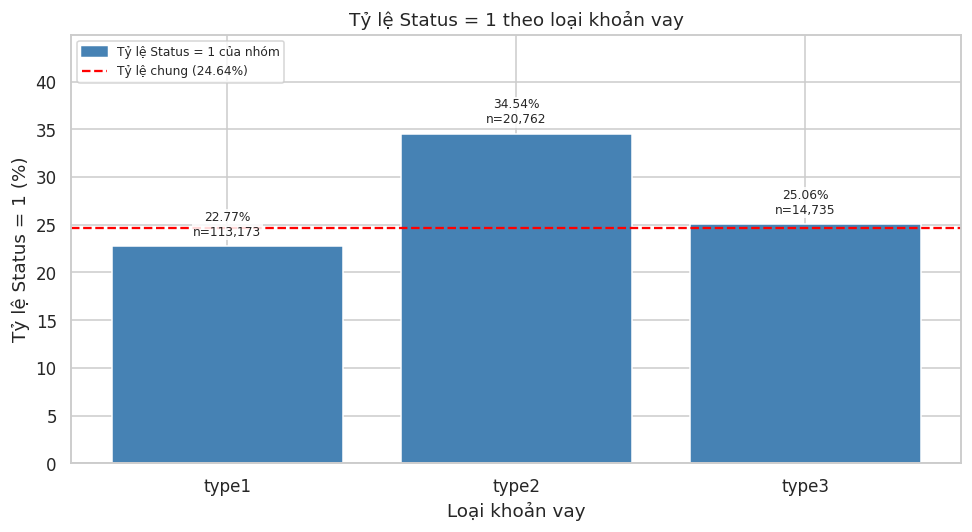

In [ ]:
# Lấy tỷ lệ Status = 1 và số quan sát của từng loại khoản vay
loan_type_rate = loan_type_percentage[1]
loan_type_n = loan_type_status.sum(axis=1)

# Vẽ biểu đồ cột so sánh tỷ lệ giữa các loại khoản vay
plot_status_rate(loan_type_rate, loan_type_n, "Tỷ lệ Status = 1 theo loại khoản vay", "Loại khoản vay", OVERALL_RATE)
plt.tight_layout()
plt.show()

In [ ]:
# Kiểm định Chi-square giữa loại khoản vay và Status
chi2_loan, p_loan, dof_loan, expected_loan = chi2_contingency(
    loan_type_status
)

# Hiển thị kết quả
print(f"Chi-square: {chi2_loan:.4f}")
print(f"Bậc tự do: {dof_loan}")
print(f"P-value: {p_loan:.4g}")
print(f"Tần số kỳ vọng nhỏ nhất: {expected_loan.min():.1f}")

Chi-square: 1309.9581
Bậc tự do: 2
P-value: 3.517e-285
Tần số kỳ vọng nhỏ nhất: 3631.4


In [ ]:
# Tính Cramér's V để đánh giá mức độ liên hệ
n_loan = loan_type_status.to_numpy().sum()

cramers_v_loan = np.sqrt(
    chi2_loan / (n_loan * (min(loan_type_status.shape) - 1))
)

print(f"Cramér's V: {cramers_v_loan:.4f} ({label_effect(cramers_v_loan)})")

Cramér's V: 0.0939 (Không đáng kể)


**Nhận xét:**

- **Phân phối:** `type2` có tỷ lệ `Status = 1` cao nhất (**34,54%**), cao hơn `type1` (22,77%) khoảng **11,77%**, tương đương 1,52 lần. `type3` (25,06%) gần với mức chung 24,64%.
- **Kiểm định:** Chi-square cho kết quả χ² = 1.309,96, p < 0,001, nên bác bỏ H₀. Tần số kỳ vọng nhỏ nhất là 3.631,4, đáp ứng điều kiện áp dụng kiểm định.
- **Mức độ liên hệ:** Cramér's V = **0,0939**, cho thấy mối liên hệ tổng thể yếu giữa loại khoản vay và `Status`, mặc dù sự khác biệt về tỷ lệ giữa `type2` và `type1` khá rõ.
- **Ý nghĩa và giới hạn:** `type2` trùng hoàn toàn với nhóm `business_or_commercial = b/c`, nên hai biến không cung cấp thông tin độc lập. Kết quả chưa xét đến các yếu tố khác như số tiền vay hoặc `credit_type`, đồng thời ý nghĩa cụ thể của các mã `loan_type` chưa được xác nhận.

## 3.3. Số tiền vay (`loan_amount`) và `Status`

- **H₀:** Phân phối `loan_amount` giống nhau giữa hai nhóm `Status`.
- **H₁:** Phân phối `loan_amount` khác nhau giữa hai nhóm `Status`.
- **Lý do chọn biến:** Số tiền vay có thể liên quan đến tình trạng khoản vay. Phân tích này nhằm kiểm tra liệu các khoản vay thuộc hai nhóm `Status` có sự khác biệt về số tiền vay hay không.

In [ ]:
# Thống kê số tiền vay theo từng nhóm Status
loan_amount_status = df_clean.groupby("Status")["loan_amount"].describe()

# Hiển thị kết quả
display(loan_amount_status.round(2).reset_index())

,Status,count,mean,std,min,25%,50%,75%,max
0,0,112031.0,334990.77,174916.57,26500.0,206500.0,306500.0,446500.0,3006500.0
1,1,36639.0,319275.18,208576.81,16500.0,176500.0,276500.0,416500.0,3576500.0


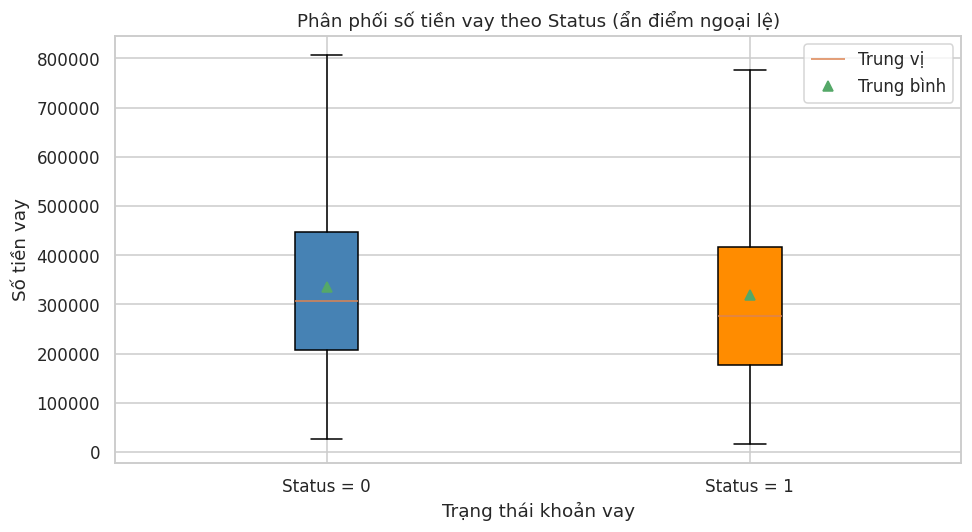

In [ ]:
# Chuẩn bị số tiền vay theo từng nhóm Status
loan_0 = df_clean.loc[df_clean["Status"] == 0, "loan_amount"]
loan_1 = df_clean.loc[df_clean["Status"] == 1, "loan_amount"]

# Vẽ biểu đồ hộp, ẩn các điểm ngoại lệ
plt.figure(figsize=(9, 5))
box = plt.boxplot(
    [loan_0, loan_1],
    tick_labels=["Status = 0", "Status = 1"],
    showfliers=False,
    showmeans=True,
    patch_artist=True
)

for patch, color in zip(box["boxes"], ["steelblue", "darkorange"]):
    patch.set_facecolor(color)

plt.title("Phân phối số tiền vay theo Status (ẩn điểm ngoại lệ)")
plt.xlabel("Trạng thái khoản vay")
plt.ylabel("Số tiền vay")
plt.legend(
    [box["medians"][0], box["means"][0]],
    ["Trung vị", "Trung bình"],
    loc="upper right"
)

plt.tight_layout()
plt.show()

In [ ]:
# Kiểm định Mann–Whitney U giữa hai nhóm Status
u_stat, p_loan_amount = mannwhitneyu(
    loan_0,
    loan_1,
    alternative="two-sided"
)

# Hiển thị kết quả
print(f"Mann–Whitney U: {u_stat:.0f}")
print(f"P-value: {p_loan_amount:.4g}")

Mann–Whitney U: 2241604248
P-value: 3.037e-155


In [ ]:
# Tính số lượng quan sát của hai nhóm
n0 = len(loan_0)
n1 = len(loan_1)

# Tính rank-biserial r để đánh giá mức độ khác biệt
rank_biserial = 2 * u_stat / (n0 * n1) - 1

print(f"Rank-biserial r: {rank_biserial:.4f} ({label_effect(rank_biserial)})")

Rank-biserial r: 0.0922 (Không đáng kể)


**Nhận xét:**

- **Phân phối:** Nhóm `Status = 1` có trung vị số tiền vay thấp hơn nhóm `Status = 0` (276.500 so với 306.500), ngược với kỳ vọng ban đầu. Tuy nhiên, nhóm `Status = 1` có độ phân tán lớn hơn và giá trị vay tối đa cũng cao hơn.
- **Kiểm định:** Mann–Whitney U cho kết quả p < 0,001, nên bác bỏ H₀. Rank-biserial r = **0,0922**, cho thấy mức độ khác biệt về thứ hạng số tiền vay giữa hai nhóm rất nhỏ.
- **Ý nghĩa và giới hạn:** Kết quả cho thấy số tiền vay có mối liên hệ yếu với `Status` khi xét riêng biến này. Phân tích chưa kiểm soát các yếu tố khác như thu nhập, giá trị tài sản hoặc đặc điểm khoản vay. Các biến `LTV` và `dtir1` sẽ được xem xét thêm ở những phần tiếp theo.

## 3.4. Điểm tín dụng (`Credit_Score`) và `Status`

- **H₀:** Phân phối `Credit_Score` giống nhau giữa hai nhóm `Status`.
- **H₁:** Phân phối `Credit_Score` khác nhau giữa hai nhóm `Status`.
- **Lý do chọn biến:** Điểm tín dụng thường được sử dụng để đánh giá mức độ rủi ro của người vay. Phân tích này nhằm kiểm tra liệu nhóm `Status = 1` có xu hướng có điểm tín dụng thấp hơn nhóm `Status = 0` hay không.

In [ ]:
# Thống kê điểm tín dụng theo từng nhóm Status
credit_status = df_clean.groupby("Status")["Credit_Score"].describe()

# Hiển thị kết quả
display(credit_status.round(2).reset_index())

,Status,count,mean,std,min,25%,50%,75%,max
0,0,112031.0,699.52,115.67,500.0,599.0,699.0,800.0,900.0
1,1,36639.0,700.60,116.49,500.0,599.5,700.0,803.0,900.0


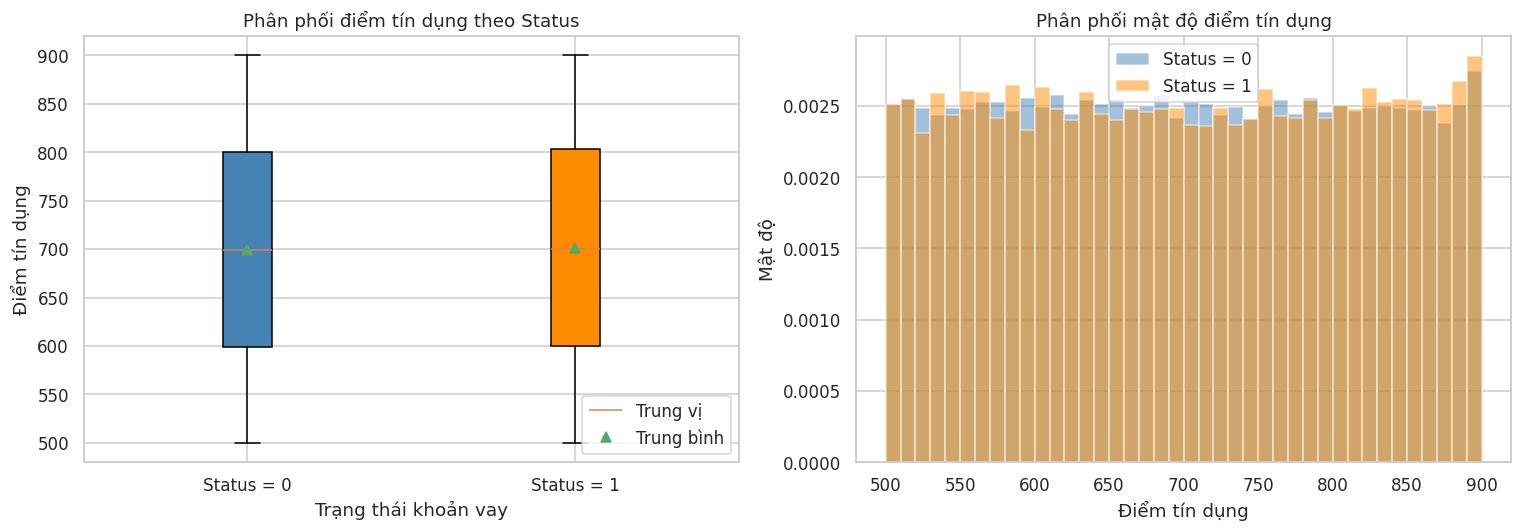

In [ ]:
# Lấy điểm tín dụng theo từng nhóm Status
credit_0 = df_clean.loc[df_clean["Status"] == 0, "Credit_Score"]
credit_1 = df_clean.loc[df_clean["Status"] == 1, "Credit_Score"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot so sánh điểm tín dụng
box = axes[0].boxplot(
    [credit_0, credit_1],
    tick_labels=["Status = 0", "Status = 1"],
    patch_artist=True,
    showmeans=True
)

for patch, color in zip(box["boxes"], ["steelblue", "darkorange"]):
    patch.set_facecolor(color)

axes[0].set_title("Phân phối điểm tín dụng theo Status")
axes[0].set_xlabel("Trạng thái khoản vay")
axes[0].set_ylabel("Điểm tín dụng")
axes[0].legend(
    [box["medians"][0], box["means"][0]],
    ["Trung vị", "Trung bình"],
    loc="lower right"
)

# Histogram mật độ với các khoảng điểm giống nhau
bins = np.linspace(500, 900, 41)

axes[1].hist(
    credit_0, bins=bins, density=True,
    alpha=0.5, color="steelblue", label="Status = 0"
)
axes[1].hist(
    credit_1, bins=bins, density=True,
    alpha=0.5, color="darkorange", label="Status = 1"
)

axes[1].set_title("Phân phối mật độ điểm tín dụng")
axes[1].set_xlabel("Điểm tín dụng")
axes[1].set_ylabel("Mật độ")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Kiểm định Mann–Whitney U giữa hai nhóm Status
u_credit, p_credit = mannwhitneyu(
    credit_0,
    credit_1,
    alternative="two-sided"
)

# Tính rank-biserial r để đánh giá mức độ khác biệt
rank_biserial_credit = (
    2 * u_credit / (len(credit_0) * len(credit_1)) - 1
)

# Hiển thị kết quả
print(f"Mann–Whitney U: {u_credit:.0f}")
print(f"P-value: {p_credit:.4g}")
print(
    f"Rank-biserial r: {rank_biserial_credit:.4f} "
    f"({label_effect(abs(rank_biserial_credit))})"
)

Mann–Whitney U: 2041392730
P-value: 0.1243
Rank-biserial r: -0.0053 (Không đáng kể)


**Nhận xét:**

- **Phân phối:** Điểm tín dụng của hai nhóm gần như tương đương, với trung vị lần lượt là 699 và 700, trung bình khoảng 699,5 và 700,6. Histogram cho thấy phân phối của hai nhóm chồng lấn rất nhiều và có dạng gần đều trong khoảng 500-900.
- **Kiểm định:** Mann-Whitney U cho kết quả **p = 0,124 > 0,05**, nên chưa đủ bằng chứng bác bỏ H₀. Rank-biserial r = **-0,0053**, cho thấy mức độ khác biệt về thứ hạng gần như bằng 0.
- **Ý nghĩa:** Kết quả không thể hiện xu hướng nhóm `Status = 1` có điểm tín dụng thấp hơn như kỳ vọng ban đầu. Đặc điểm phân phối gần đều cũng đáng chú ý, nhưng chưa đủ cơ sở để xác định nguyên nhân.
- **Giới hạn:** Kết quả này chỉ cho thấy chưa phát hiện sự khác biệt có ý nghĩa thống kê giữa hai nhóm. Không thể kết luận rằng điểm tín dụng không có giá trị trong thực tế hoặc hai phân phối hoàn toàn giống nhau.

## 3.5. Thu nhập (`income`) và `Status`

- **H₀:** Phân phối `income` giống nhau giữa hai nhóm `Status`.
- **H₁:** Phân phối `income` khác nhau giữa hai nhóm `Status`.
- **Lý do chọn biến:** Thu nhập có thể liên quan đến khả năng trả nợ. Phân tích này nhằm kiểm tra liệu nhóm `Status = 1` có xu hướng có thu nhập thấp hơn nhóm `Status = 0` hay không.
- **Xử lý dữ liệu thiếu:** Sử dụng `df_clean` và loại các giá trị `NaN` của `income` khi phân tích. Các giá trị thiếu được giữ nguyên ở Giai đoạn 2 để tránh thay thế khi chưa có đủ cơ sở.

In [ ]:
# Thống kê thu nhập theo từng nhóm Status
income_status = df_clean.groupby("Status")["income"].describe()

# Hiển thị kết quả
display(income_status.round(2).reset_index())

,Status,count,mean,std,min,25%,50%,75%,max
0,0,104120.0,7204.01,6201.34,0.0,4020.0,6000.0,8760.0,377220.0
1,1,35400.0,6231.81,7247.65,0.0,3000.0,4860.0,7620.0,578580.0


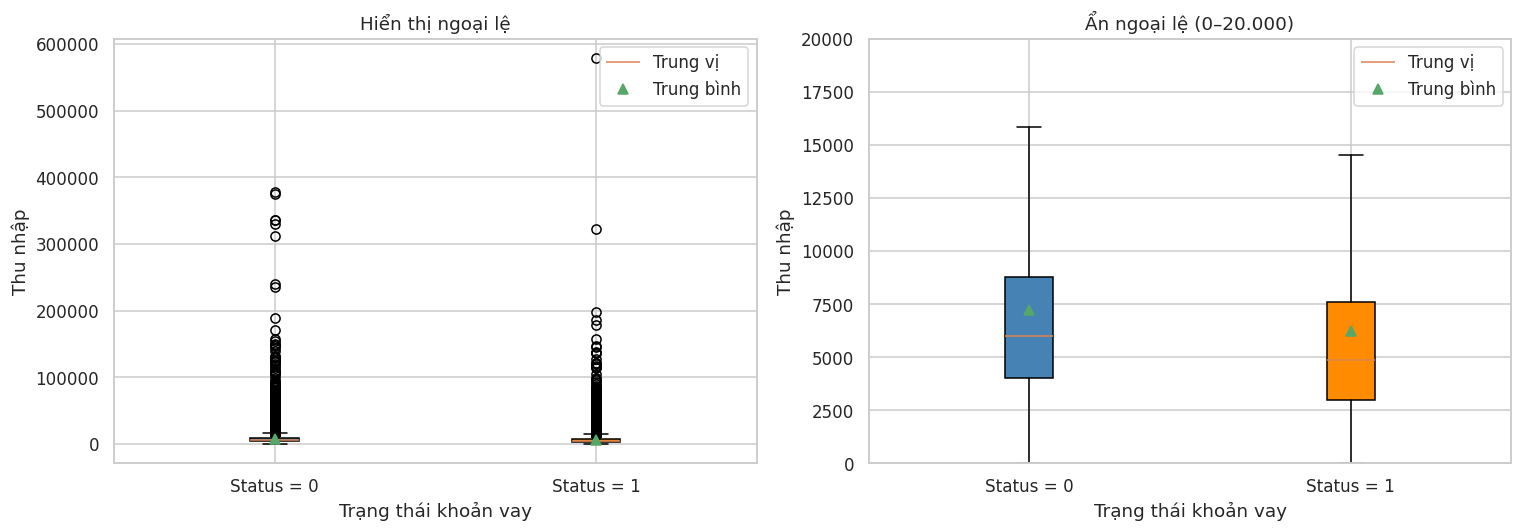

In [ ]:
# Lấy thu nhập theo từng nhóm Status, bỏ giá trị thiếu
income_0 = df_clean.loc[df_clean["Status"] == 0, "income"].dropna()
income_1 = df_clean.loc[df_clean["Status"] == 1, "income"].dropna()

# Vẽ hai boxplot để so sánh phân phối thu nhập
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, show_fliers, title in [
    (axes[0], True, "Hiển thị ngoại lệ"),
    (axes[1], False, "Ẩn ngoại lệ (0–20.000)")
]:
    box = ax.boxplot(
        [income_0, income_1],
        tick_labels=["Status = 0", "Status = 1"],
        showfliers=show_fliers,
        showmeans=True,
        patch_artist=True
    )

    for patch, color in zip(box["boxes"], ["steelblue", "darkorange"]):
        patch.set_facecolor(color)

    ax.set_title(title)
    ax.set_xlabel("Trạng thái khoản vay")
    ax.set_ylabel("Thu nhập")
    ax.legend(
        [box["medians"][0], box["means"][0]],
        ["Trung vị", "Trung bình"],
        loc="upper right"
    )

# Phóng to vùng thu nhập phổ biến ở biểu đồ bên phải
axes[1].set_ylim(0, 20000)

plt.tight_layout()
plt.show()

In [ ]:
# Kiểm định Mann–Whitney U giữa hai nhóm thu nhập
u_income, p_income = mannwhitneyu(
    income_0,
    income_1,
    alternative="two-sided"
)

# Hiển thị kết quả
print(f"Mann–Whitney U: {u_income:.0f}")
print(f"P-value: {format_p(p_income)}")

Mann–Whitney U: 2183040824
P-value: < 1e-300


In [ ]:
# Tính số lượng quan sát có thu nhập trong mỗi nhóm
n_income_0 = len(income_0)
n_income_1 = len(income_1)

# Tính rank-biserial r để đánh giá mức độ khác biệt
rank_biserial_income = (
    2 * u_income / (n_income_0 * n_income_1) - 1
)

print(
    f"Rank-biserial r: {rank_biserial_income:.4f} "
    f"({label_effect(abs(rank_biserial_income))})"
)

Rank-biserial r: 0.1846 (Nhỏ)


In [ ]:
# So sánh kết quả kiểm định khi giữ và loại income = 0
income_sensitivity = pd.DataFrame({
    "Giữ income = 0": mann_whitney_report(income_0, income_1),
    "Loại income = 0": mann_whitney_report(
        income_0[income_0 > 0],
        income_1[income_1 > 0]
    )
}).T

# Định dạng p-value
income_sensitivity["p-value"] = income_sensitivity["p-value"].apply(format_p)

display(income_sensitivity.reset_index().rename(columns={"index": "Trường hợp"}))

,Trường hợp,U,p-value,Rank-biserial r,Mức độ,n (Status=0),n (Status=1),Median (Status=0),Median (Status=1)
0,Giữ income = 0,2183040824.0,< 1e-300,0.1846,Nhỏ,104120,35400,6000.0,4860.0
1,Loại income = 0,2052687592.0,< 1e-300,0.1547,Nhỏ,104112,34148,6000.0,5040.0


**Nhận xét:**

- **Phân phối:** Nhóm `Status = 1` có trung vị thu nhập **4.860**, thấp hơn nhóm `Status = 0` (**6.000**) khoảng 19%. Cả hai nhóm đều có nhiều giá trị ngoại lệ lớn, khiến sự khác biệt khó quan sát trên biểu đồ đầy đủ.
- **Kiểm định:** Mann–Whitney U cho kết quả **p < 10⁻³⁰⁰**, nên bác bỏ H₀. Rank-biserial r = **0,1846**, cho thấy mức độ khác biệt nhỏ, với xu hướng thu nhập cao hơn ở nhóm `Status = 0`.
- **Phân tích độ nhạy:** Khi loại 1.260 quan sát có `income = 0`, rank-biserial r giảm từ **0,1846 xuống 0,1547**. Tuy nhiên, chiều khác biệt và ý nghĩa thống kê vẫn không thay đổi. Điều này cho thấy kết quả không hoàn toàn phụ thuộc vào các giá trị thu nhập bằng 0.
- **Giới hạn:** Tỷ lệ thiếu thu nhập khác nhau giữa hai nhóm `Status`, có thể ảnh hưởng đến kết quả so sánh. Ngoài ra, đơn vị và kỳ tính thu nhập chưa được xác nhận, nên chỉ diễn giải sự khác biệt tương đối giữa hai nhóm.

## 3.6. Khu vực (`Region`) và `Status`

- **H₀:** `Region` và `Status` độc lập với nhau.
- **H₁:** Có mối liên hệ giữa `Region` và `Status`.
- **Lý do chọn biến:** Phân tích nhằm kiểm tra liệu tỷ lệ `Status = 1` có khác nhau giữa các khu vực hay không. Kết quả giúp nhận diện sự khác biệt theo khu vực, nhưng không chứng minh vị trí địa lý là nguyên nhân dẫn đến tình trạng khoản vay.

In [ ]:
# Đếm số lượng quan sát theo khu vực và Status
region_status = pd.crosstab(
    df_clean["Region"],
    df_clean["Status"]
)

# Hiển thị kết quả
display(region_status.reset_index().rename_axis(None, axis=1))

,Region,0,1
0,Central,6302,2395
1,North,57901,16821
2,North-East,859,376
3,South,46969,17047


In [ ]:
# Tính tỷ lệ phần trăm Status trong từng khu vực
region_percentage = region_status.div(
    region_status.sum(axis=1), axis=0
) * 100

# Hiển thị kết quả
display(
    region_percentage.round(2)
    .reset_index()
    .rename_axis(None, axis=1)
)

,Region,0,1
0,Central,72.46,27.54
1,North,77.49,22.51
2,North-East,69.55,30.45
3,South,73.37,26.63


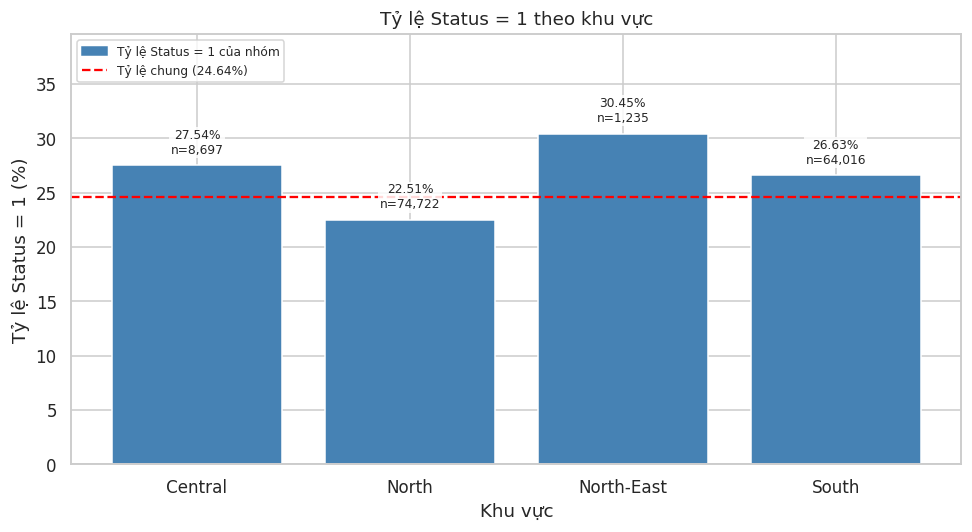

In [ ]:
# Lấy tỷ lệ Status = 1 và số quan sát của từng khu vực
region_rate = region_percentage[1]
region_n = region_status.sum(axis=1)

# Vẽ biểu đồ tỷ lệ Status = 1 theo khu vực
plot_status_rate(
    region_rate,
    region_n,
    "Tỷ lệ Status = 1 theo khu vực",
    "Khu vực",
    OVERALL_RATE
)

plt.tight_layout()
plt.show()

In [ ]:
# Kiểm định Chi-square giữa Region và Status
chi2_region, p_region, dof_region, expected_region = chi2_contingency(
    region_status
)

# Hiển thị kết quả
print(f"Chi-square: {chi2_region:.4f}")
print(f"Bậc tự do: {dof_region}")
print(f"P-value: {p_region:.4g}")
print(f"Tần số kỳ vọng nhỏ nhất: {expected_region.min():.1f}")

Chi-square: 380.4563
Bậc tự do: 3
P-value: 3.786e-82
Tần số kỳ vọng nhỏ nhất: 304.4


In [ ]:
# Tính Cramér's V để đánh giá mức độ liên hệ
n_region = region_status.to_numpy().sum()

cramers_v_region = np.sqrt(
    chi2_region / (n_region * (min(region_status.shape) - 1))
)

print(
    f"Cramér's V: {cramers_v_region:.4f} "
    f"({label_effect(cramers_v_region)})"
)

Cramér's V: 0.0506 (Không đáng kể)


**Nhận xét:**

- **Phân phối:** `North-East` có tỷ lệ `Status = 1` cao nhất (**30,45%**), nhưng chỉ có 1.235 quan sát. `North` có tỷ lệ thấp nhất (**22,51%**), trong khi `Central` (27,54%) và `South` (26,63%) đều cao hơn mức chung 24,64%.
- **Kiểm định:** Chi-square cho kết quả χ² = 380,46, p < 0,001, nên bác bỏ H₀. Các tần số kỳ vọng đáp ứng điều kiện áp dụng kiểm định.
- **Mức độ liên hệ:** Cramér's V = **0,051**, cho thấy mối liên hệ giữa `Region` và `Status` rất yếu, dù có ý nghĩa thống kê.
- **Ý nghĩa và giới hạn:** Sự khác biệt giữa các khu vực có thể liên quan đến điều kiện kinh tế hoặc đặc điểm khoản vay, nhưng phân tích hiện tại chưa kiểm soát các yếu tố này. Vì vậy, không thể kết luận khu vực trực tiếp ảnh hưởng đến tình trạng khoản vay hoặc sử dụng kết quả làm căn cứ từ chối tín dụng theo khu vực.

## 3.7. Ma trận tương quan giữa các thuộc tính tài chính

- **Mục tiêu:** Xem xét mức độ và chiều tương quan giữa các thuộc tính tài chính, đồng thời phát hiện những cặp biến có tương quan cao hoặc có thể chứa thông tin trùng lặp.
- **Phương pháp:** Sử dụng cả Pearson và Spearman. Pearson đo mối liên hệ tuyến tính, trong khi Spearman đo mối liên hệ đơn điệu dựa trên thứ hạng và ít nhạy hơn với các giá trị ngoại lệ.
- **Xử lý dữ liệu thiếu:** Giữ nguyên các giá trị `NaN` trong `df_clean`. Khi tính tương quan, mỗi cặp biến chỉ sử dụng những quan sát có đủ giá trị của cả hai biến (*pairwise deletion*).

In [ ]:
# Chọn các thuộc tính tài chính
financial_cols = [
    "loan_amount",
    "income",
    "property_value",
    "LTV",
    "dtir1"
]

# Tính tương quan Pearson và Spearman
correlation = df_clean[financial_cols].corr(method="pearson")
correlation_spearman = df_clean[financial_cols].corr(method="spearman")

print("Tương quan Pearson:")
display(correlation.round(2))

print("Tương quan Spearman:")
display(correlation_spearman.round(2))

# Đếm số quan sát có đủ dữ liệu cho từng cặp biến
valid = df_clean[financial_cols].notna().astype(int)
pair_counts = valid.T @ valid

print("Số quan sát sử dụng cho từng cặp biến:")
display(pair_counts)

Tương quan Pearson:


,loan_amount,income,property_value,LTV,dtir1
loan_amount,1.00,0.46,0.73,0.04,0.02
income,0.46,1.00,0.41,-0.07,-0.27
property_value,0.73,0.41,1.00,-0.22,-0.06
LTV,0.04,-0.07,-0.22,1.00,0.16
dtir1,0.02,-0.27,-0.06,0.16,1.00


Tương quan Spearman:


,loan_amount,income,property_value,LTV,dtir1
loan_amount,1.00,0.64,0.86,0.08,0.02
income,0.64,1.00,0.61,-0.02,-0.31
property_value,0.86,0.61,1.00,-0.36,-0.05
LTV,0.08,-0.02,-0.36,1.00,0.16
dtir1,0.02,-0.31,-0.05,0.16,1.00


Số quan sát sử dụng cho từng cặp biến:


,loan_amount,income,property_value,LTV,dtir1
loan_amount,148670,139520,133572,133572,124549
income,139520,139520,124437,124437,124439
property_value,133572,124437,133572,133572,124547
LTV,133572,124437,133572,133572,124547
dtir1,124549,124439,124547,124547,124549


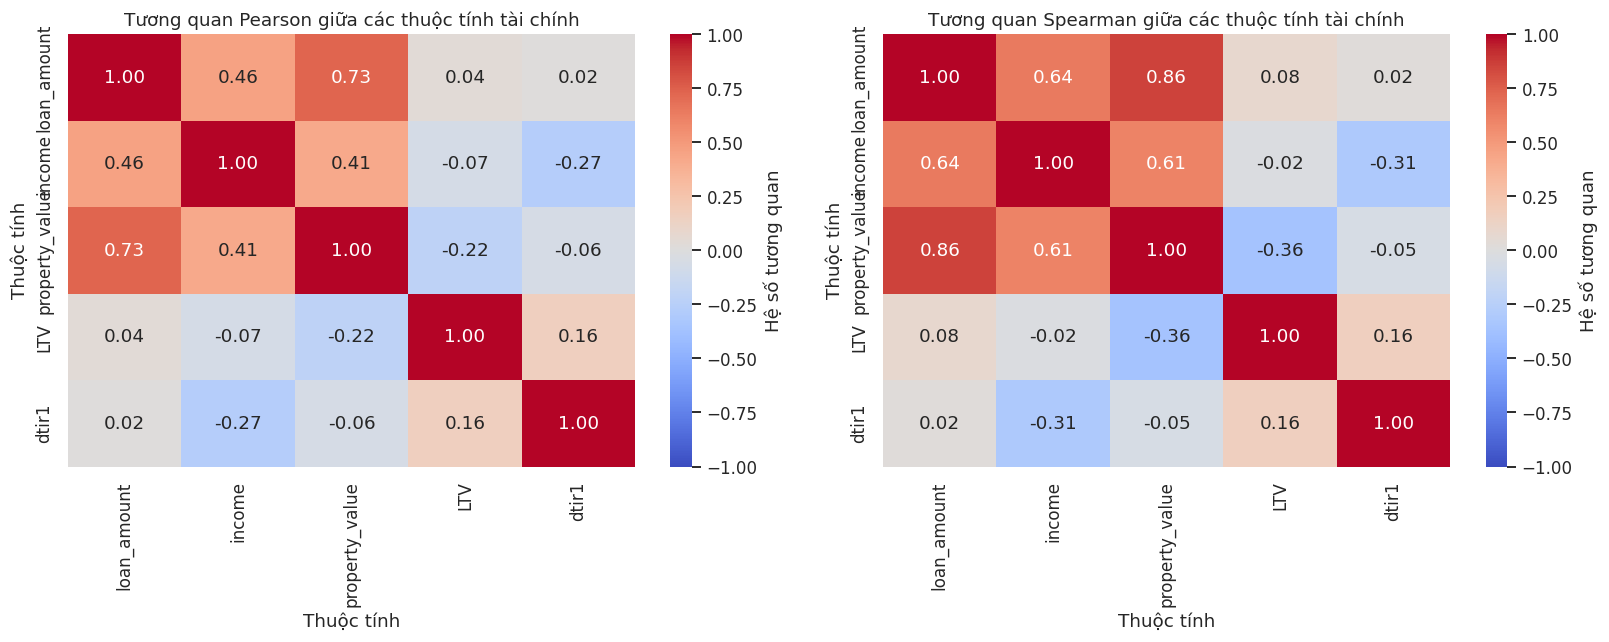

In [ ]:
# Vẽ hai Heatmap cạnh nhau để so sánh tương quan Pearson và Spearman
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, matrix, name in [(axes[0], correlation, "Pearson"), (axes[1], correlation_spearman, "Spearman")]:
    sns.heatmap(
        matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1,
        ax=ax,
        cbar_kws={"label": "Hệ số tương quan"}
    )
    ax.set_title(f"Tương quan {name} giữa các thuộc tính tài chính")
    ax.set_xlabel("Thuộc tính")
    ax.set_ylabel("Thuộc tính")

plt.tight_layout()
plt.show()

**Nhận xét:**

- **Tương quan nổi bật:** `loan_amount` và `property_value` có tương quan dương mạnh nhất (Pearson = 0,73; Spearman = 0,86). `income` cũng có tương quan dương với hai biến này, đặc biệt theo Spearman (0,61–0,64). Điều này cho thấy các khoản vay lớn thường đi kèm giá trị tài sản và thu nhập cao hơn.
- **So sánh Pearson và Spearman:** Một số cặp biến có hệ số Spearman lớn hơn Pearson về độ lớn, chẳng hạn `loan_amount`–`income` (0,64 so với 0,46). Sự khác biệt này có thể liên quan đến ngoại lệ hoặc hình dạng mối quan hệ giữa các biến, nhưng cần phân tích thêm để xác định nguyên nhân.
- **Các tỷ lệ tài chính:** `LTV` tương quan âm với `property_value` (Spearman = -0,36), phù hợp với việc giá trị tài sản nằm ở mẫu số của công thức LTV. `income` cũng tương quan âm với `dtir1` (Spearman = −0,31), phù hợp với ý nghĩa của tỷ lệ nợ trên thu nhập.
- **Giới hạn:** Các kết quả chỉ phản ánh tương quan giữa từng cặp thuộc tính, chưa đủ để kết luận về đa cộng tuyến trong một mô hình cụ thể. Ngoài ra, mỗi hệ số được tính trên những quan sát có đủ dữ liệu của cặp biến tương ứng, nên tình trạng thiếu dữ liệu có thể ảnh hưởng đến kết quả.

## 3.8. Loại hồ sơ tín dụng (`credit_type`) và `Status`

- **H₀:** `credit_type` và `Status` độc lập với nhau.
- **H₁:** Có mối liên hệ giữa `credit_type` và `Status`.
- **Lý do chọn biến:** Ở mục 3.4, `Credit_Score` không cho thấy sự khác biệt có ý nghĩa thống kê giữa hai nhóm `Status`. Vì vậy, phân tích này nhằm kiểm tra liệu tỷ lệ `Status = 1` có khác nhau giữa các loại hồ sơ tín dụng hay không.
- **Lưu ý:** Ý nghĩa cụ thể của các mã `EXP`, `EQUI`, `CRIF` và `CIB` chưa được xác nhận trong tài liệu nguồn.

In [ ]:
# Thống kê số lượng và tỷ lệ Status theo credit_type
credit_type_status = pd.crosstab(
    df_clean["credit_type"],
    df_clean["Status"]
)

credit_type_percentage = (
    credit_type_status.div(credit_type_status.sum(axis=1), axis=0) * 100
)

# Gộp số lượng và tỷ lệ vào cùng một bảng
credit_type_table = pd.DataFrame({
    "Status=0": credit_type_status[0],
    "Status=1": credit_type_status[1],
    "Status=0 (%)": credit_type_percentage[0].round(2),
    "Status=1 (%)": credit_type_percentage[1].round(2)
})

display(credit_type_table.reset_index())

# Kiểm định Chi-square và Cramér's V
credit_type_test = chi_square_report(credit_type_status)

credit_type_test["p-value"] = format_p(credit_type_test["p-value"])

display(pd.DataFrame([credit_type_test]))

,credit_type,Status=0,Status=1,Status=0 (%),Status=1 (%)
0,CIB,40542,7610,84.20,15.80
1,CRIF,36774,7127,83.77,16.23
2,EQUI,1,15297,0.01,99.99
3,EXP,34714,6605,84.01,15.99


,Chi-square,df,p-value,Cramér's V,Mức độ,Tần số kỳ vọng nhỏ nhất,% ô có kỳ vọng < 5
0,52135.2807,3,< 1e-300,0.5922,Lớn,3770.1,0.0


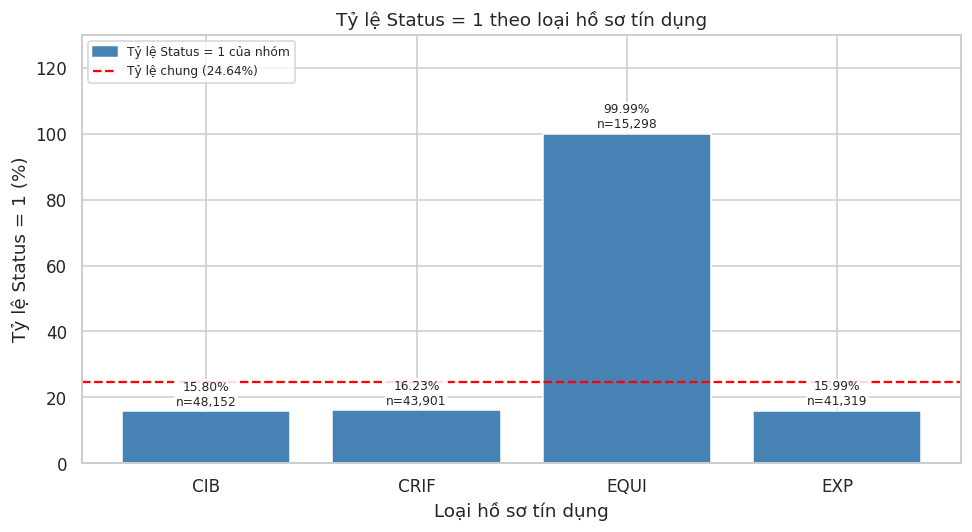

In [ ]:
# Vẽ biểu đồ tỷ lệ Status = 1 theo loại hồ sơ tín dụng
plot_status_rate(
    credit_type_percentage[1],
    credit_type_status.sum(axis=1),
    "Tỷ lệ Status = 1 theo loại hồ sơ tín dụng",
    "Loại hồ sơ tín dụng",
    OVERALL_RATE
)

plt.tight_layout()
plt.show()

In [ ]:
# Kiểm tra dữ liệu thiếu Interest_rate_spread theo credit_type
missing_spread = pd.crosstab(
    df_clean["credit_type"],
    df_clean["Interest_rate_spread"].isna()
)

missing_spread.columns = ["Không thiếu", "Thiếu"]
display(missing_spread.reset_index())

# Tỷ lệ Status = 1 khi loại nhóm EQUI
non_equi = df_clean["credit_type"] != "EQUI"

rate_non_equi = df_clean.loc[non_equi, "Status"].mean() * 100

# Tỷ lệ khoản vay Status = 1 thuộc nhóm EQUI
status_1 = df_clean["Status"] == 1

equi_share = (
    df_clean.loc[status_1, "credit_type"].eq("EQUI").mean() * 100
)

print(f"Tỷ lệ Status = 1 khi loại EQUI: {rate_non_equi:.2f}%")
print(f"Tỷ lệ nhóm Status = 1 thuộc EQUI: {equi_share:.2f}%")

,credit_type,Không thiếu,Thiếu
0,CIB,40542,7610
1,CRIF,36774,7127
2,EQUI,1,15297
3,EXP,34714,6605


Tỷ lệ Status = 1 khi loại EQUI: 16.00%
Tỷ lệ nhóm Status = 1 thuộc EQUI: 41.75%


**Nhận xét:**

- **Phân phối:** `EQUI` có tỷ lệ `Status = 1` gần như tuyệt đối (**99,99%**, tương ứng 15.297/15.298 quan sát), trong khi ba nhóm còn lại chỉ khoảng 15,8–16,2%.
- **Kiểm định:** Chi-square cho kết quả χ² = 52.135,28, p < 0,001, nên bác bỏ H₀. Cramér's V = **0,5922**, cho thấy mối liên hệ mạnh giữa `credit_type` và `Status`.
- **Ảnh hưởng của EQUI:** Nhóm `EQUI` chiếm **41,75%** tổng số quan sát có `Status = 1`. Khi loại nhóm này, tỷ lệ `Status = 1` trong phần dữ liệu còn lại giảm từ 24,64% xuống khoảng 16%.
- **Dữ liệu thiếu:** Có 15.297/15.298 quan sát thuộc `EQUI` thiếu `Interest_rate_spread`. Đây là một đặc điểm đáng chú ý, nhưng chưa đủ để xác định nguyên nhân.
- **Ý nghĩa và giới hạn:** Mối liên hệ gần như tuyệt đối giữa `EQUI` và `Status` cần được kiểm tra thêm. Nếu xây dựng mô hình dự đoán, cần xác minh ý nghĩa và thời điểm ghi nhận `credit_type` để đánh giá nguy cơ rò rỉ nhãn (*target leakage*). Kết quả này không chứng minh loại hồ sơ tín dụng trực tiếp gây ra tình trạng khoản vay.

## 3.9. Đặc điểm cấu trúc trả nợ: `Neg_ammortization` và `lump_sum_payment`

- **H₀:** Mỗi biến `Neg_ammortization` và `lump_sum_payment` độc lập với `Status`.
- **H₁:** Có mối liên hệ giữa ít nhất một trong hai biến và `Status`.
- **Lý do chọn biến:** Hai biến này phản ánh đặc điểm của phương thức trả nợ. Phân tích nhằm kiểm tra liệu tỷ lệ `Status = 1` có khác nhau giữa các nhóm khoản vay hay không.
- **Xử lý dữ liệu thiếu:** Nhóm `Unknown` của `Neg_ammortization` (121 quan sát) được loại khỏi phép so sánh hai nhóm và kiểm định Chi-square.

In [ ]:
# Xác định nhóm có đặc điểm và nhóm tham chiếu
structure_specs = {
    "Neg_ammortization": ("neg_amm", "not_neg"),
    "lump_sum_payment": ("lpsm", "not_lpsm")
}

structure_results = {}

for col, (exposed, reference) in structure_specs.items():
    # Chỉ lấy hai nhóm cần so sánh
    table = pd.crosstab(
        df_clean[col],
        df_clean["Status"]
    ).loc[[exposed, reference]]

    # Tính tỷ lệ Status = 1 trong mỗi nhóm
    rate = table[1] / table.sum(axis=1) * 100

    # Kiểm định Chi-square và tính Cramér's V
    result = chi_square_report(table)

    # Bổ sung tỷ lệ và Risk Ratio
    result["Tỷ lệ nhóm có đặc điểm (%)"] = round(rate[exposed], 2)
    result["Tỷ lệ nhóm tham chiếu (%)"] = round(rate[reference], 2)
    result["Risk Ratio"] = round(rate[exposed] / rate[reference], 2)
    result["n nhóm có đặc điểm"] = int(table.loc[exposed].sum())

    result["p-value"] = format_p(result["p-value"])
    structure_results[col] = result

    print(f"Bảng tần số: {col}")
    display(table.reset_index().rename_axis(None, axis=1))

# Tổng hợp kết quả
structure_summary = pd.DataFrame(structure_results).T

display(
    structure_summary.rename_axis("Thuộc tính").reset_index()
)

Bảng tần số: Neg_ammortization


,Neg_ammortization,0,1
0,neg_amm,8382,6747
1,not_neg,103560,29860


Bảng tần số: lump_sum_payment


,lump_sum_payment,0,1
0,lpsm,756,2628
1,not_lpsm,111275,34011


,Thuộc tính,Chi-square,df,p-value,Cramér's V,Mức độ,Tần số kỳ vọng nhỏ nhất,% ô có kỳ vọng < 5,Tỷ lệ nhóm có đặc điểm (%),Tỷ lệ nhóm tham chiếu (%),Risk Ratio,n nhóm có đặc điểm
0,Neg_ammortization,3610.2081,1,< 1e-300,0.1559,Nhỏ,3728.2,0.0,44.6,22.38,1.99,15129
1,lump_sum_payment,5237.8274,1,< 1e-300,0.1877,Nhỏ,834.0,0.0,77.66,23.41,3.32,3384


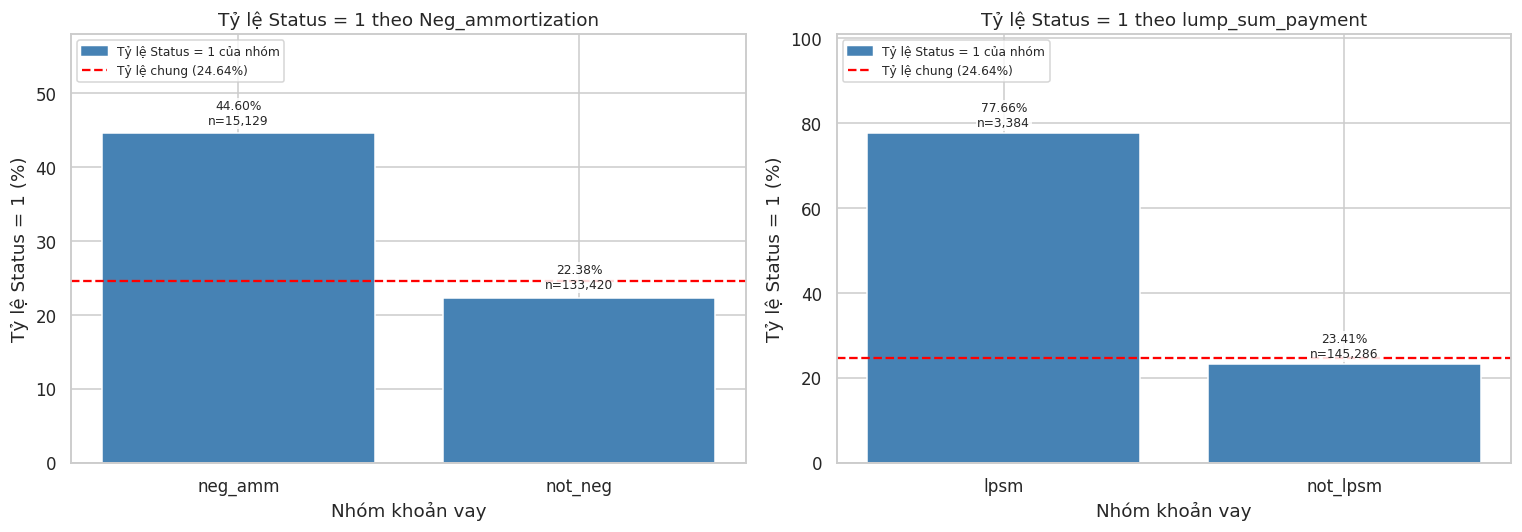

In [ ]:
# Vẽ tỷ lệ Status = 1 theo hai đặc điểm cấu trúc trả nợ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (col, (exposed, reference)) in zip(axes, structure_specs.items()):
    table = pd.crosstab(
        df_clean[col],
        df_clean["Status"]
    ).loc[[exposed, reference]]

    rate = table[1] / table.sum(axis=1) * 100
    counts = table.sum(axis=1)

    plot_status_rate(
        rate,
        counts,
        f"Tỷ lệ Status = 1 theo {col}",
        "Nhóm khoản vay",
        OVERALL_RATE,
        ax=ax
    )

plt.tight_layout()
plt.show()

**Nhận xét:**

- **`Neg_ammortization`:** Nhóm `neg_amm` có tỷ lệ `Status = 1` là **44,60%**, cao gần gấp đôi nhóm `not_neg` (22,38%), với **RR = 1,99**. Cramér's V = **0,1559**, cho thấy mức độ liên hệ nhỏ.
- **`lump_sum_payment`:** Nhóm `lpsm` có tỷ lệ `Status = 1` lên tới **77,66%**, so với 23,41% ở nhóm `not_lpsm`, tương ứng **RR = 3,32**. Tuy nhiên, nhóm `lpsm` chỉ có 3.384 quan sát. Cramér's V = **0,1877**, mức độ liên hệ nhỏ.
- **Kiểm định:** Cả hai biến đều có p < 0,001, nên bác bỏ H₀ trong từng kiểm định. Các bảng đều đáp ứng điều kiện về tần số kỳ vọng.
- **Ý nghĩa và giới hạn:** Hai đặc điểm cấu trúc trả nợ có sự khác biệt đáng chú ý về tỷ lệ `Status = 1`, đặc biệt là `lump_sum_payment`. Tuy nhiên, phân tích chưa kiểm soát các yếu tố khác như thu nhập, LTV hoặc loại khoản vay. Vì vậy, kết quả chỉ cho thấy mối liên hệ, không chứng minh cấu trúc trả nợ trực tiếp gây ra tình trạng khoản vay.

## 3.10. `LTV` và `Status`: Phân tích ảnh hưởng của dữ liệu thiếu

- **H₀:** Phân phối `LTV` giống nhau giữa hai nhóm `Status` có dữ liệu LTV.
- **H₁:** Phân phối `LTV` khác nhau giữa hai nhóm `Status` có dữ liệu LTV.
- **Lý do chọn biến:** `LTV` thể hiện tỷ lệ số tiền vay so với giá trị tài sản. Phân tích nhằm kiểm tra mối liên hệ giữa `LTV` và `Status`.
- **Vấn đề dữ liệu thiếu:** `LTV` thiếu ở khoảng 41,20% nhóm `Status = 1`, nhưng gần như không thiếu ở nhóm `Status = 0`. Vì vậy, nếu chỉ sử dụng các giá trị có sẵn, kết quả có thể bị ảnh hưởng bởi sự khác biệt về tình trạng thiếu dữ liệu.
- **Phương pháp:** Chia `LTV` thành các khoảng, bổ sung nhóm **“Thiếu dữ liệu”** để xem xét phân bố `Status`. Đồng thời, thực hiện kiểm định Mann–Whitney U trên những quan sát có giá trị LTV và báo cáo rõ cỡ mẫu.

In [ ]:
# Chia LTV thành các nhóm, giữ riêng giá trị thiếu
ltv_labels = ["≤60", "60–80", "80–90", "90–100", ">100"]

ltv_group = pd.cut(
    df_clean["LTV"],
    bins=[0, 60, 80, 90, 100, np.inf],
    labels=ltv_labels,
    include_lowest=True
)

ltv_group = ltv_group.cat.add_categories("Thiếu dữ liệu").fillna("Thiếu dữ liệu")

# Thống kê số lượng và tỷ lệ Status = 1
ltv_status = pd.crosstab(ltv_group, df_clean["Status"])
ltv_rate = ltv_status[1] / ltv_status.sum(axis=1) * 100

ltv_table = pd.DataFrame({
    "Status=0": ltv_status[0],
    "Status=1": ltv_status[1],
    "Tỷ lệ Status=1 (%)": ltv_rate.round(2)
})

display(ltv_table.rename_axis("Nhóm LTV").reset_index())

# Chi-square trên toàn bộ nhóm, bao gồm dữ liệu thiếu
ltv_test = chi_square_report(ltv_status)
ltv_test["p-value"] = format_p(ltv_test["p-value"])

# Chi-square chỉ trên các nhóm có LTV
ltv_test_observed = chi_square_report(
    ltv_status.drop(index="Thiếu dữ liệu")
)
ltv_test_observed["p-value"] = format_p(ltv_test_observed["p-value"])

display(pd.DataFrame({
    "Có nhóm thiếu dữ liệu": ltv_test,
    "Chỉ nhóm có LTV": ltv_test_observed
}).T.rename_axis("Trường hợp").reset_index())

# Mann–Whitney U trên các giá trị LTV có sẵn
ltv_0 = df_clean.loc[df_clean["Status"] == 0, "LTV"].dropna()
ltv_1 = df_clean.loc[df_clean["Status"] == 1, "LTV"].dropna()

ltv_mw = mann_whitney_report(ltv_0, ltv_1)
ltv_mw["p-value"] = format_p(ltv_mw["p-value"])

display(pd.DataFrame([ltv_mw]))

,Nhóm LTV,Status=0,Status=1,Tỷ lệ Status=1 (%)
0,≤60,28031,4534,13.92
1,60–80,43439,6456,12.94
2,80–90,21331,4822,18.44
3,90–100,18600,4560,19.69
4,>100,628,1171,65.09
5,Thiếu dữ liệu,2,15096,99.99


,Trường hợp,Chi-square,df,p-value,Cramér's V,Mức độ,Tần số kỳ vọng nhỏ nhất,% ô có kỳ vọng < 5
0,Có nhóm thiếu dữ liệu,54279.4134,5,< 1e-300,0.6042,Lớn,443.4,0.0
1,Chỉ nhóm có LTV,4000.7954,4,< 1e-300,0.1731,Nhỏ,290.1,0.0


,U,p-value,Rank-biserial r,Mức độ,n (Status=0),n (Status=1),Median (Status=0),Median (Status=1)
0,1.035994e+09,6.022e-238,-0.1415,Nhỏ,112029,21543,74.504405,79.362416


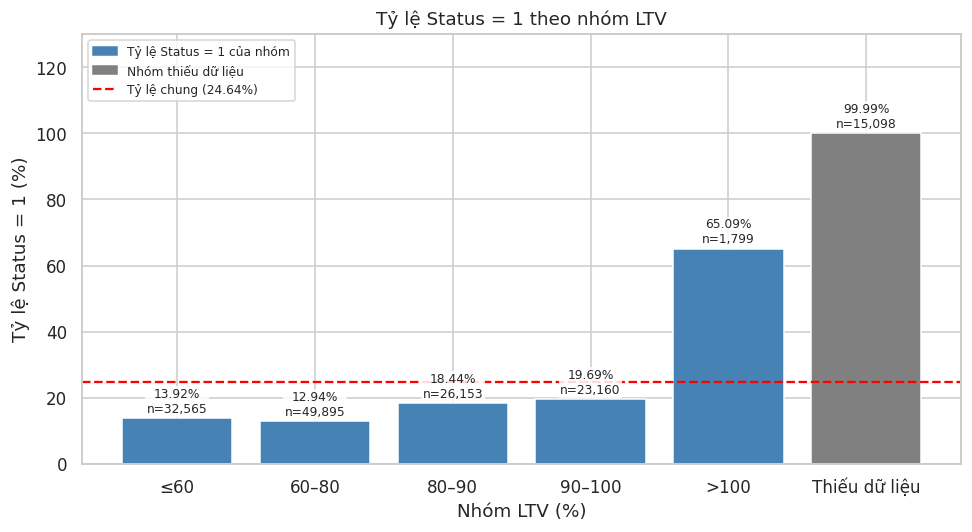

In [ ]:
# Vẽ tỷ lệ Status = 1 theo nhóm LTV, làm nổi bật nhóm thiếu dữ liệu
plot_status_rate(
    ltv_rate,
    ltv_status.sum(axis=1),
    "Tỷ lệ Status = 1 theo nhóm LTV",
    "Nhóm LTV (%)",
    OVERALL_RATE,
    highlight_missing=True
)

plt.tight_layout()
plt.show()

**Nhận xét:**

- **Các nhóm có LTV:** Tỷ lệ `Status = 1` dao động từ **12,94% đến 19,69%** ở các nhóm LTV không vượt quá 100%, nhưng tăng lên **65,09%** ở nhóm LTV trên 100%. Nhóm này có 1.799 quan sát.
- **Kiểm định:** Khi chỉ xét các nhóm có LTV, Chi-square cho p < 0,001 và Cramér's V = **0,1731**, cho thấy mức độ liên hệ nhỏ. Kiểm định Mann–Whitney cũng cho p < 0,001, với trung vị LTV của nhóm `Status = 1` cao hơn nhóm `Status = 0` (79,36 so với 74,50) và rank-biserial r = **−0,1415**.
- **Ảnh hưởng của dữ liệu thiếu:** Trong 15.098 quan sát thiếu LTV, có **15.096 quan sát thuộc `Status = 1`**. Khi đưa nhóm thiếu dữ liệu vào bảng Chi-square, Cramér's V tăng lên **0,6042**. Điều này cho thấy tình trạng thiếu LTV có mối liên hệ rất mạnh với `Status` và ảnh hưởng đáng kể đến kết quả phân tích tổng thể.
- **Ý nghĩa và giới hạn:** Nhóm LTV trên 100% có tỷ lệ `Status = 1` cao hơn rõ rệt so với các nhóm còn lại. Tuy nhiên, kết quả chỉ phản ánh dữ liệu có LTV được ghi nhận. Việc thiếu dữ liệu không đồng đều giữa hai nhóm `Status`, cùng với sáu giá trị LTV cực đoan nghi ngờ lỗi, cần được cân nhắc khi diễn giải. Chưa thể kết luận quan hệ nhân quả.

## 3.11. Tỷ lệ nợ trên thu nhập (`dtir1`) và `Status`

- **H₀:** Phân phối `dtir1` giống nhau giữa hai nhóm `Status` có dữ liệu.
- **H₁:** Phân phối `dtir1` khác nhau giữa hai nhóm `Status` có dữ liệu.
- **Lý do chọn biến:** `dtir1` phản ánh tỷ lệ nghĩa vụ nợ so với thu nhập. Phân tích nhằm kiểm tra liệu nhóm `Status = 1` có xu hướng có DTI cao hơn nhóm `Status = 0` hay không.
- **Vấn đề dữ liệu thiếu:** `dtir1` thiếu ở 44,52% nhóm `Status = 1`, so với 6,97% nhóm `Status = 0`. Sự khác biệt này có thể ảnh hưởng đến kết quả phân tích.
- **Phương pháp:** Tương tự mục 3.10, chia DTI thành các khoảng và giữ riêng nhóm "Thiếu dữ liệu". Đồng thời, thực hiện kiểm định Mann–Whitney U trên các giá trị có sẵn và báo cáo rõ cỡ mẫu.

In [ ]:
# Chia dtir1 thành các nhóm, giữ riêng giá trị thiếu
dti_labels = ["≤20", "20–36", "36–43", "43–50", ">50"]

dti_group = pd.cut(
    df_clean["dtir1"],
    bins=[0, 20, 36, 43, 50, np.inf],
    labels=dti_labels,
    include_lowest=True
)

dti_group = dti_group.cat.add_categories("Thiếu dữ liệu").fillna("Thiếu dữ liệu")

# Thống kê số lượng và tỷ lệ Status = 1
dti_status = pd.crosstab(dti_group, df_clean["Status"])
dti_rate = dti_status[1] / dti_status.sum(axis=1) * 100

dti_table = pd.DataFrame({
    "Status=0": dti_status[0],
    "Status=1": dti_status[1],
    "Tỷ lệ Status=1 (%)": dti_rate.round(2)
})

display(dti_table.rename_axis("Nhóm DTI").reset_index())

# Chi-square có và không có nhóm thiếu dữ liệu
dti_test = chi_square_report(dti_status)
dti_test["p-value"] = format_p(dti_test["p-value"])

dti_test_observed = chi_square_report(
    dti_status.drop(index="Thiếu dữ liệu")
)
dti_test_observed["p-value"] = format_p(dti_test_observed["p-value"])

display(
    pd.DataFrame({
        "Có nhóm thiếu dữ liệu": dti_test,
        "Chỉ nhóm có DTI": dti_test_observed
    }).T.rename_axis("Trường hợp").reset_index()
)

# Mann–Whitney U trên các giá trị DTI có sẵn
dti_0 = df_clean.loc[df_clean["Status"] == 0, "dtir1"].dropna()
dti_1 = df_clean.loc[df_clean["Status"] == 1, "dtir1"].dropna()

dti_mw = mann_whitney_report(dti_0, dti_1)
dti_mw["p-value"] = format_p(dti_mw["p-value"])

display(pd.DataFrame([dti_mw]))

,Nhóm DTI,Status=0,Status=1,Tỷ lệ Status=1 (%)
0,≤20,6189,1976,24.20
1,20–36,36183,4935,12.00
2,36–43,31199,4658,12.99
3,43–50,25702,5068,16.47
4,>50,4947,3692,42.74
5,Thiếu dữ liệu,7811,16310,67.62


,Trường hợp,Chi-square,df,p-value,Cramér's V,Mức độ,Tần số kỳ vọng nhỏ nhất,% ô có kỳ vọng < 5
0,Có nhóm thiếu dữ liệu,32777.2661,5,< 1e-300,0.4695,Trung bình,2012.2,0.0
1,Chỉ nhóm có DTI,5638.0753,4,< 1e-300,0.2128,Nhỏ,1332.7,0.0


,U,p-value,Rank-biserial r,Mức độ,n (Status=0),n (Status=1),Median (Status=0),Median (Status=1)
0,901116149.5,6.890e-250,-0.1494,Nhỏ,104220,20329,38.0,42.0


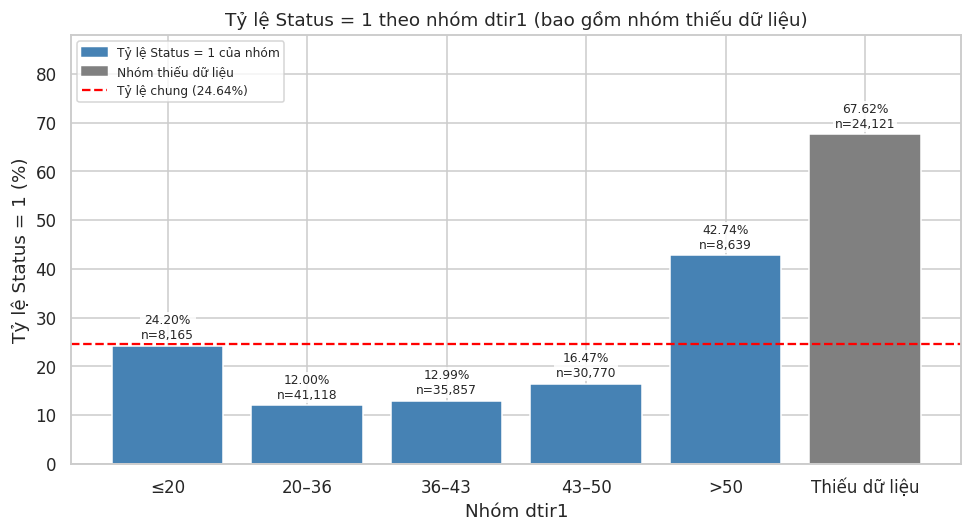

In [ ]:
# Biểu đồ tỷ lệ Status = 1 theo nhóm dtir1, nhóm thiếu dữ liệu được tô màu khác
plot_status_rate(dti_rate, dti_status.sum(axis=1),
                 "Tỷ lệ Status = 1 theo nhóm dtir1 (bao gồm nhóm thiếu dữ liệu)", "Nhóm dtir1",
                 OVERALL_RATE, highlight_missing=True)
plt.tight_layout()
plt.show()

**Nhận xét:**

- **Phân phối:** Trong các nhóm có dữ liệu, tỷ lệ `Status = 1` thấp nhất ở khoảng `dtir1` từ 20–36 (**12,00%**) và 36–43 (**12,99%**). Tỷ lệ tăng lên **42,74%** ở nhóm trên 50, nhưng nhóm ≤20 cũng có tỷ lệ khá cao (**24,20%**). Điều này cho thấy mối liên hệ không tăng đều theo `dtir1`.
- **Kiểm định:** Khi chỉ xét các nhóm có dữ liệu, Chi-square cho p < 0,001 và Cramér's V = **0,2128**, cho thấy mức độ liên hệ nhỏ. Kiểm định Mann–Whitney cũng cho p < 0,001, với trung vị `dtir1` của nhóm `Status = 1` cao hơn nhóm `Status = 0` (42 so với 38) và rank-biserial r = **−0,1494**.
- **Ảnh hưởng của dữ liệu thiếu:** Trong 24.121 quan sát thiếu `dtir1`, có 16.310 quan sát thuộc `Status = 1` (**67,62%**). Khi đưa nhóm thiếu dữ liệu vào kiểm định Chi-square, Cramér's V tăng từ **0,2128 lên 0,4695**, cho thấy tình trạng thiếu `dtir1` có liên hệ đáng kể với `Status`.
- **Ý nghĩa và giới hạn:** Nhóm có `dtir1` trên 50 có tỷ lệ `Status = 1` cao hơn rõ rệt so với các nhóm còn lại, nhưng chưa thể xác định nguyên nhân. Kiểm định Mann–Whitney chỉ sử dụng **20.329/36.639** quan sát thuộc `Status = 1`. Ngoài ra, đơn vị và cách tính chính xác của `dtir1` chưa được xác nhận, nên các ngưỡng phân nhóm chỉ mang tính tham khảo.

## 3.12. Tổng hợp kết quả kiểm định và hiệu chỉnh Bonferroni

Bảng dưới đây tổng hợp các kiểm định đã thực hiện trong Giai đoạn 3, bao gồm p-value và effect size để đánh giá cả ý nghĩa thống kê lẫn mức độ liên hệ.

Do thực hiện nhiều kiểm định, phương pháp **Bonferroni** được áp dụng với ngưỡng ý nghĩa điều chỉnh bằng 0,05 chia cho số kiểm định trong nhóm giả thuyết chính.

Các kết quả được sắp xếp theo độ lớn effect size để thuận tiện so sánh. Tuy nhiên, Cramér's V và rank-biserial r là hai thước đo khác nhau nên không thể so sánh trực tiếp hoàn toàn.

Chỉ báo thiếu `Interest_rate_spread` được trình bày riêng làm **mốc tham chiếu về tình trạng thiếu dữ liệu gắn với `Status`**, không được xem là yếu tố rủi ro tín dụng.

In [ ]:
# Gom kết quả kiểm định vào một bảng tổng hợp
test_rows = []

def add_chi_square(name, table, reference=False):
    result = chi_square_report(table)

    test_rows.append({
        "Biến": name,
        "Kiểm định": "Chi-square",
        "Thống kê": result["Chi-square"],
        "p-value": result["p-value"],
        "Effect size": "Cramér's V",
        "Giá trị effect size": result["Cramér's V"],
        "n": table.to_numpy().sum(),
        "Tham chiếu": reference
    })

def add_mann_whitney(name, column):
    group_0 = df_clean.loc[df_clean["Status"] == 0, column].dropna()
    group_1 = df_clean.loc[df_clean["Status"] == 1, column].dropna()

    result = mann_whitney_report(group_0, group_1)

    test_rows.append({
        "Biến": name,
        "Kiểm định": "Mann–Whitney U",
        "Thống kê": result["U"],
        "p-value": result["p-value"],
        "Effect size": "Rank-biserial r",
        "Giá trị effect size": result["Rank-biserial r"],
        "n": len(group_0) + len(group_1),
        "Tham chiếu": False
    })

# Chỉ báo thiếu dữ liệu: dùng làm mốc tham chiếu
add_chi_square(
    "Thiếu Interest_rate_spread",
    pd.crosstab(
        df_clean["Interest_rate_spread"].isna(),
        df_clean["Status"]
    ),
    reference=True
)

# Các biến phân loại
add_chi_square("credit_type", credit_type_status)
add_chi_square("Nhóm LTV (có nhóm thiếu)", ltv_status)
add_chi_square("Nhóm dtir1 (có nhóm thiếu)", dti_status)

add_chi_square(
    "lump_sum_payment",
    pd.crosstab(df_clean["lump_sum_payment"], df_clean["Status"])
)

add_chi_square(
    "Neg_ammortization (bỏ Unknown)",
    pd.crosstab(
        df_clean["Neg_ammortization"],
        df_clean["Status"]
    ).drop(index="Unknown")
)

add_chi_square("loan_type", loan_type_status)
add_chi_square("Region", region_status)
add_chi_square("age (bỏ Unknown)", age_table)

# Các biến số
add_mann_whitney("income (giá trị có sẵn)", "income")
add_mann_whitney("LTV (giá trị có sẵn)", "LTV")
add_mann_whitney("dtir1 (giá trị có sẵn)", "dtir1")
add_mann_whitney("loan_amount", "loan_amount")
add_mann_whitney("Credit_Score", "Credit_Score")

# Tạo bảng tổng hợp
test_summary = pd.DataFrame(test_rows)

# Chỉ tính Bonferroni cho các kiểm định không phải tham chiếu
n_tests = (~test_summary["Tham chiếu"]).sum()
bonferroni_alpha = 0.05 / n_tests

test_summary["Có ý nghĩa sau Bonferroni"] = np.where(
    test_summary["Tham chiếu"],
    "Không áp dụng",
    np.where(
        test_summary["p-value"] < bonferroni_alpha,
        "Có",
        "Không"
    )
)

# Đánh giá độ lớn effect size
test_summary["Mức độ"] = (
    test_summary["Giá trị effect size"]
    .abs()
    .apply(label_effect)
)

# Sắp xếp theo độ lớn effect size
test_summary = test_summary.sort_values(
    "Giá trị effect size",
    key=lambda x: x.abs(),
    ascending=False
).reset_index(drop=True)

# Định dạng kết quả
test_summary["p-value"] = test_summary["p-value"].apply(format_p)
test_summary["Thống kê"] = test_summary["Thống kê"].round(2)
test_summary["Giá trị effect size"] = (
    test_summary["Giá trị effect size"].round(4)
)

print(f"Số kiểm định chính: {n_tests}")
print(f"Ngưỡng Bonferroni: {bonferroni_alpha:.5f}")

display(test_summary.drop(columns="Tham chiếu"))

Số kiểm định chính: 13
Ngưỡng Bonferroni: 0.00385


,Biến,Kiểm định,Thống kê,p-value,Effect size,Giá trị effect size,n,Có ý nghĩa sau Bonferroni,Mức độ
0,Thiếu Interest_rate_spread,Chi-square,1.486646e+05,< 1e-300,Cramér's V,1.0000,148670,Không áp dụng,Lớn
1,Nhóm LTV (có nhóm thiếu),Chi-square,5.427941e+04,< 1e-300,Cramér's V,0.6042,148670,Có,Lớn
2,credit_type,Chi-square,5.213528e+04,< 1e-300,Cramér's V,0.5922,148670,Có,Lớn
3,Nhóm dtir1 (có nhóm thiếu),Chi-square,3.277727e+04,< 1e-300,Cramér's V,0.4695,148670,Có,Trung bình
4,lump_sum_payment,Chi-square,5.237830e+03,< 1e-300,Cramér's V,0.1877,148670,Có,Nhỏ
5,income (giá trị có sẵn),Mann–Whitney U,2.183041e+09,< 1e-300,Rank-biserial r,0.1846,139520,Có,Nhỏ
6,Neg_ammortization (bỏ Unknown),Chi-square,3.610210e+03,< 1e-300,Cramér's V,0.1559,148549,Có,Nhỏ
7,dtir1 (giá trị có sẵn),Mann–Whitney U,9.011161e+08,6.890e-250,Rank-biserial r,-0.1494,124549,Có,Nhỏ
8,LTV (giá trị có sẵn),Mann–Whitney U,1.035994e+09,6.022e-238,Rank-biserial r,-0.1415,133572,Có,Nhỏ
9,loan_type,Chi-square,1.309960e+03,3.517e-285,Cramér's V,0.0939,148670,Có,Không đáng kể


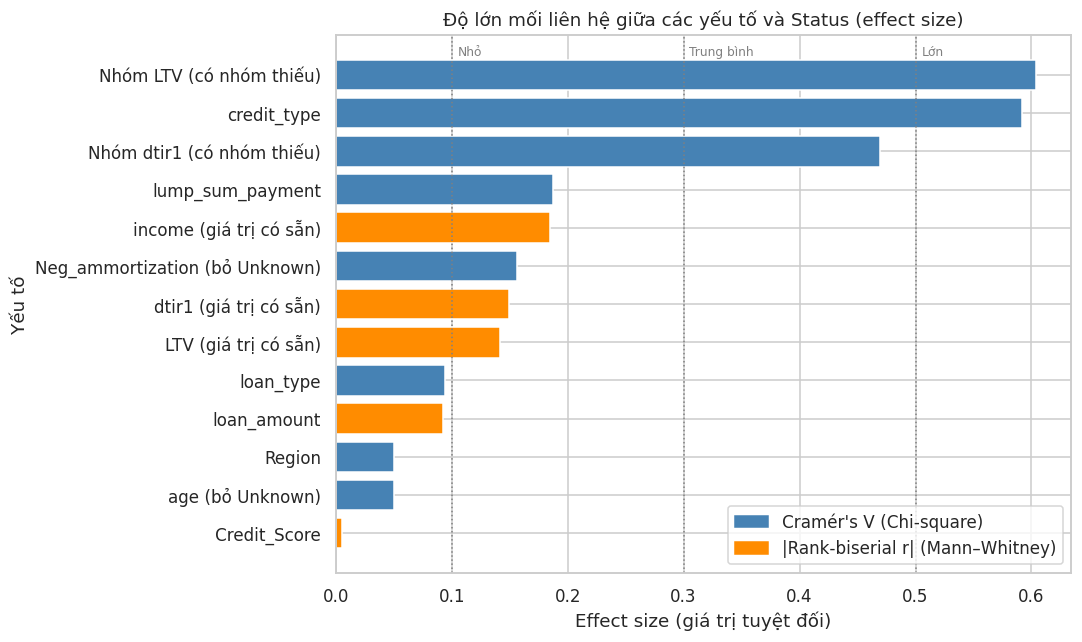

In [ ]:
# Bỏ hàng tham chiếu rò rỉ
effect_plot = test_summary[~test_summary["Tham chiếu"]].copy()

# Đảm bảo effect size là số
effect_plot["Giá trị effect size"] = pd.to_numeric(
    effect_plot["Giá trị effect size"], errors="coerce"
)

# Lấy trị tuyệt đối để so sánh độ mạnh
effect_plot["|Effect size|"] = effect_plot["Giá trị effect size"].abs()

# Sắp xếp tăng dần để vẽ barh
effect_plot = effect_plot.sort_values("|Effect size|")

# Tô màu theo loại kiểm định
colors = effect_plot["Kiểm định"].map({
    "Chi-square": "steelblue",
    "Mann–Whitney U": "darkorange"
})

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(effect_plot["Biến"], effect_plot["|Effect size|"], color=colors)

# Các ngưỡng diễn giải Cohen
for threshold, name in [(0.1, "Nhỏ"), (0.3, "Trung bình"), (0.5, "Lớn")]:
    ax.axvline(threshold, color="grey", linestyle=":", linewidth=1)
    ax.text(threshold + 0.005, len(effect_plot) - 0.5, name, fontsize=8, color="grey")

# Chú giải
ax.legend(handles=[
    Patch(color="steelblue", label="Cramér's V (Chi-square)"),
    Patch(color="darkorange", label="|Rank-biserial r| (Mann–Whitney)")
], loc="lower right")

ax.set_title("Độ lớn mối liên hệ giữa các yếu tố và Status (effect size)")
ax.set_xlabel("Effect size (giá trị tuyệt đối)")
ax.set_ylabel("Yếu tố")

plt.tight_layout()
plt.show()

**Nhận xét tổng hợp:**

- **Ý nghĩa thống kê:** Trong 13 kiểm định chính, có **12 kiểm định đạt ý nghĩa thống kê** sau hiệu chỉnh Bonferroni (ngưỡng α = 0,00385). Chỉ `Credit_Score` không đạt ý nghĩa thống kê (p = 0,124). Do cỡ mẫu lớn, cần xem xét cả effect size thay vì chỉ dựa vào p-value.

- **Mối liên hệ mạnh nhất:** Nhóm LTV có tính cả dữ liệu thiếu (Cramér's V = **0,6042**) và `credit_type` (**0,5922**) có mức liên hệ lớn nhất trong các kiểm định chính. Nhóm `dtir1` có tính cả dữ liệu thiếu cũng có mức liên hệ đáng kể (V = **0,4695**). Tuy nhiên, các kết quả này chịu ảnh hưởng của tình trạng thiếu dữ liệu hoặc những nhóm có phân bố `Status` rất khác biệt, nên cần diễn giải thận trọng.

- **Các mối liên hệ nhỏ:** `lump_sum_payment` (V = 0,1877), `income` (|r| = 0,1846), `Neg_ammortization` (V = 0,1559), `dtir1` (|r| = 0,1494) và `LTV` (|r| = 0,1415) trên các giá trị có sẵn đều cho thấy mức độ liên hệ nhỏ với `Status`.

- **Các mối liên hệ rất yếu:** `loan_type`, `loan_amount`, `Region` và `age` đều có effect size dưới 0,1 dù đạt ý nghĩa thống kê. Riêng `Credit_Score` có effect size gần bằng 0 và không đạt ý nghĩa thống kê.

- **Giới hạn:** Cramér's V và rank-biserial r đo những khía cạnh khác nhau nên thứ tự trong biểu đồ chỉ mang tính tham khảo. Các kiểm định đều là phân tích đơn biến, chưa kiểm soát các yếu tố gây nhiễu và không chứng minh quan hệ nhân quả.

## 3.13. Kiểm tra độ bền của kết quả khi loại nhóm `EQUI`

**Lý do:** Ở mục 3.8, nhóm `credit_type = EQUI` có tỷ lệ `Status = 1` gần như tuyệt đối (99,99%) và chiếm 41,75% tổng số quan sát thuộc `Status = 1`. Điều này đặt ra câu hỏi liệu các mối liên hệ đã phát hiện có phụ thuộc nhiều vào nhóm `EQUI` hay không.

**Phương pháp:** Loại nhóm `EQUI` và thực hiện lại các kiểm định chính trên tập dữ liệu còn lại (`df_non_equi`, gồm 133.372 quan sát). Sau đó, so sánh chiều và độ lớn effect size trước và sau khi loại nhóm này.

**Mục tiêu:** Đánh giá mức độ ổn định của các kết quả khi thay đổi thành phần mẫu, không nhằm xác định nhóm `EQUI` là dữ liệu sai.

In [ ]:
# Tạo tập dữ liệu không gồm nhóm EQUI
df_non_equi = df_clean.loc[
    df_clean["credit_type"] != "EQUI"
].copy()

print(f"Số khoản vay: {len(df_non_equi):,}")
print(f"Tỷ lệ Status = 1: {df_non_equi['Status'].mean() * 100:.2f}%")

# Kiểm tra tỷ lệ thiếu dữ liệu trong nhóm Status = 1
non_equi_status_1 = df_non_equi["Status"] == 1

for col in ["LTV", "dtir1"]:
    missing_rate = (
        df_non_equi.loc[non_equi_status_1, col].isna().mean() * 100
    )
    print(f"Tỷ lệ thiếu {col} (Status = 1): {missing_rate:.2f}%")


# Tạo bảng chéo, loại Unknown nếu có
def category_table(frame, column):
    table = pd.crosstab(frame[column], frame["Status"])
    return table.drop(index="Unknown", errors="ignore")


# So sánh effect size trước và sau khi loại EQUI
robust_rows = []

# Biến phân loại
for col in ["lump_sum_payment", "Neg_ammortization", "loan_type", "Region", "age"]:
    robust_rows.append({
        "Biến": col,
        "Effect size": "Cramér's V",
        "Toàn bộ dữ liệu": chi_square_report(
            category_table(df_clean, col)
        )["Cramér's V"],
        "Loại EQUI": chi_square_report(
            category_table(df_non_equi, col)
        )["Cramér's V"]
    })

# Biến số
for col in ["income", "dtir1", "LTV", "loan_amount", "Credit_Score"]:
    full_0 = df_clean.loc[df_clean["Status"] == 0, col].dropna()
    full_1 = df_clean.loc[df_clean["Status"] == 1, col].dropna()

    subset_0 = df_non_equi.loc[df_non_equi["Status"] == 0, col].dropna()
    subset_1 = df_non_equi.loc[df_non_equi["Status"] == 1, col].dropna()

    robust_rows.append({
        "Biến": col,
        "Effect size": "Rank-biserial r",
        "Toàn bộ dữ liệu": mann_whitney_report(
            full_0, full_1
        )["Rank-biserial r"],
        "Loại EQUI": mann_whitney_report(
            subset_0, subset_1
        )["Rank-biserial r"]
    })

# Hiển thị bảng so sánh
robustness = pd.DataFrame(robust_rows)

robustness["Mức độ khi loại EQUI"] = (
    robustness["Loại EQUI"].abs().apply(label_effect)
)

display(robustness.round(4))

Số khoản vay: 133,372
Tỷ lệ Status = 1: 16.00%
Tỷ lệ thiếu LTV (Status = 1): 0.00%
Tỷ lệ thiếu dtir1 (Status = 1): 4.75%


,Biến,Effect size,Toàn bộ dữ liệu,Loại EQUI,Mức độ khi loại EQUI
0,lump_sum_payment,Cramér's V,0.1877,0.1770,Nhỏ
1,Neg_ammortization,Cramér's V,0.1559,0.1486,Nhỏ
2,loan_type,Cramér's V,0.0939,0.1063,Nhỏ
3,Region,Cramér's V,0.0506,0.0504,Không đáng kể
4,age,Cramér's V,0.0502,0.0509,Không đáng kể
5,income,Rank-biserial r,0.1846,0.2262,Nhỏ
6,dtir1,Rank-biserial r,-0.1494,-0.1494,Nhỏ
7,LTV,Rank-biserial r,-0.1415,-0.1392,Nhỏ
8,loan_amount,Rank-biserial r,0.0922,0.1222,Nhỏ
9,Credit_Score,Rank-biserial r,-0.0053,-0.0057,Không đáng kể


In [ ]:
# So sánh tỷ lệ Status = 1 trước và sau khi loại EQUI
group_compare = {}

for name, groups in [("LTV", ltv_group), ("dtir1", dti_group)]:

    # Tỷ lệ Status = 1 trên toàn bộ dữ liệu
    full_rate = df_clean.groupby(groups, observed=True)["Status"].mean() * 100

    # Tỷ lệ và số quan sát sau khi loại EQUI
    non_equi_groups = groups.loc[df_non_equi.index]

    non_equi_table = df_non_equi.groupby(
        non_equi_groups, observed=True
    )["Status"].agg(["mean", "count"])

    # Gộp kết quả
    group_compare[name] = pd.DataFrame({
        "Toàn bộ (%)": full_rate.round(2),
        "Loại EQUI (%)": (non_equi_table["mean"] * 100).round(2),
        "n (loại EQUI)": non_equi_table["count"]
    })

    print(f"So sánh theo nhóm {name}:")
    display(group_compare[name].rename_axis("Nhóm").reset_index())

So sánh theo nhóm LTV:


,Nhóm,Toàn bộ (%),Loại EQUI (%),n (loại EQUI)
0,≤60,13.92,13.90,32556
1,60–80,12.94,12.86,49846
2,80–90,18.44,18.20,26078
3,90–100,19.69,19.45,23091
4,>100,65.09,65.09,1799
5,Thiếu dữ liệu,99.99,0.00,2


So sánh theo nhóm dtir1:


,Nhóm,Toàn bộ (%),Loại EQUI (%),n (loại EQUI)
0,≤20,24.20,24.20,8165
1,20–36,12.00,12.00,41117
2,36–43,12.99,12.99,35856
3,43–50,16.47,16.47,30770
4,>50,42.74,42.74,8639
5,Thiếu dữ liệu,67.62,11.49,8825


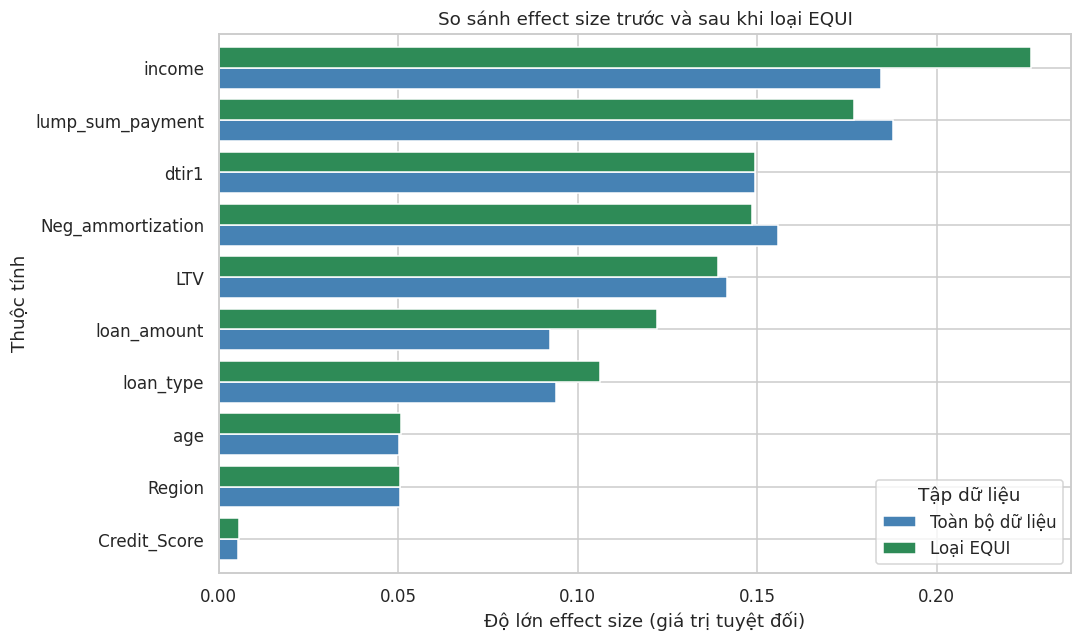

In [ ]:
# Chuẩn bị dữ liệu so sánh effect size
robust_plot = (
    robustness.set_index("Biến")[["Toàn bộ dữ liệu", "Loại EQUI"]]
    .abs()
    .sort_values("Loại EQUI")
)

# Vẽ biểu đồ cột ngang
ax = robust_plot.plot(
    kind="barh",
    figsize=(10, 6),
    color=["steelblue", "seagreen"],
    width=0.8
)

# Tiêu đề và nhãn trục
ax.set_title("So sánh effect size trước và sau khi loại EQUI")
ax.set_xlabel("Độ lớn effect size (giá trị tuyệt đối)")
ax.set_ylabel("Thuộc tính")
ax.legend(title="Tập dữ liệu")

plt.tight_layout()
plt.show()

**Nhận xét:**

- **Ảnh hưởng của `EQUI`:** Sau khi loại nhóm `EQUI`, dữ liệu còn **133.372 khoản vay**, với tỷ lệ `Status = 1` giảm từ 24,64% xuống **16,00%**. Tỷ lệ thiếu LTV trong nhóm `Status = 1` giảm từ 41,20% xuống 0%, còn tỷ lệ thiếu `dtir1` giảm từ 44,52% xuống 4,75%.

- **Các kết quả tương đối ổn định:** Mức độ liên hệ của `lump_sum_payment` (V: 0,188 → 0,177), `Neg_ammortization` (0,156 → 0,149), `LTV` (r: −0,142 → −0,139) và `dtir1` (r ≈ −0,149) thay đổi ít. Tỷ lệ `Status = 1` ở nhóm LTV trên 100% vẫn là **65,09%**, còn nhóm `dtir1` trên 50 vẫn là **42,74%**.

- **Các biến có mức độ liên hệ tăng:** Rank-biserial r của `income` tăng từ **0,1846 lên 0,2262**, còn `loan_amount` tăng từ 0,0922 lên 0,1222. Cramér's V của `loan_type` cũng tăng từ 0,0939 lên 0,1063. Điều này cho thấy mức độ liên hệ của một số biến thay đổi khi loại `EQUI`.

- **Các biến có liên hệ rất yếu:** `age` và `Region` gần như không thay đổi, trong khi `Credit_Score` tiếp tục có effect size gần bằng 0.

- **Dữ liệu thiếu:** Tỷ lệ `Status = 1` trong nhóm thiếu `dtir1` giảm từ **67,62% xuống 11,49%** khi loại `EQUI`. Điều này cho thấy kết quả liên hệ mạnh giữa tình trạng thiếu `dtir1` và `Status` trên toàn bộ dữ liệu phụ thuộc đáng kể vào nhóm `EQUI`.

- **Kết luận:** Nhiều mối liên hệ vẫn giữ nguyên chiều và có độ lớn tương đối ổn định sau khi loại `EQUI`. Tuy nhiên, kết quả cũng cho thấy thành phần mẫu ảnh hưởng đáng kể đến một số effect size và cách diễn giải dữ liệu thiếu. Phân tích này không loại bỏ được các yếu tố gây nhiễu hoặc chứng minh quan hệ nhân quả.

# Giai đoạn 4. Đánh giá tác động và khuyến nghị

> **Giả định làm việc:** Các khuyến nghị dưới đây tạm coi `Status = 1` là nhóm khoản vay **vỡ nợ/có vấn đề**, dựa trên mô tả bài toán của data card (*"classify if any new borrower is likely to default"*). Tuy nhiên, ý nghĩa chính thức của mã `Status` chưa được tài liệu xác nhận. Nếu cách mã hóa thực tế khác, các khuyến nghị về rủi ro cần được đánh giá lại. Các phát hiện về tình trạng thiếu dữ liệu và mối liên hệ giữa các thuộc tính ở mục 4.1-A vẫn có giá trị về mặt thống kê.

## 4.1. Các phát hiện nổi bật

Các nhận xét dưới đây sử dụng quy ước `Status = 1` là nhóm khoản vay vỡ nợ hoặc có vấn đề. Ý nghĩa chính thức của mã `Status` chưa được xác nhận, nên các diễn giải về rủi ro vẫn mang tính giả định.

### A. Chất lượng dữ liệu và nguy cơ rò rỉ thông tin

| Phát hiện | Bằng chứng |
|---|---|
| Tình trạng thiếu `Interest_rate_spread` trùng hoàn toàn với `Status = 1` | Toàn bộ 36.639 khoản `Status = 1` đều thiếu, trong khi không khoản `Status = 0` nào thiếu. Cramér's V = 1,000. |
| Xóa toàn bộ dòng có giá trị thiếu sẽ làm mất nhóm `Status = 1` | Sau `dropna()`, chỉ còn 98.187 quan sát, tất cả thuộc `Status = 0`. |
| `credit_type = EQUI` có liên hệ đặc biệt mạnh với `Status` | 15.297/15.298 khoản `EQUI` thuộc `Status = 1` (99,99%). Cramér's V = 0,5922. |
| Tình trạng thiếu LTV có liên quan chặt chẽ đến nhóm `EQUI` | Sau khi loại `EQUI`, không còn khoản `Status = 1` nào thiếu LTV. |
| Một số giá trị bất thường cần xác minh | Có 6 khoản LTV trên 1.000%, 1.260 khoản `income = 0` và phân phối `Credit_Score` có dạng gần đều. |

Những phát hiện này cho thấy cần đặc biệt thận trọng khi xử lý dữ liệu thiếu và sử dụng các thuộc tính có liên hệ gần như tuyệt đối với `Status`. Nguy cơ rò rỉ thông tin cần được xác minh dựa trên ý nghĩa và thời điểm ghi nhận các biến.

### B. Các mối liên hệ đáng chú ý với `Status`

| Yếu tố | Kết quả chính | Effect size |
|---|---|---|
| `lump_sum_payment = lpsm` | Tỷ lệ `Status = 1` là 77,66%, so với 23,41% ở nhóm tham chiếu (RR = 3,32). | V = 0,1877 |
| `Neg_ammortization = neg_amm` | Tỷ lệ 44,60%, so với 22,38% (RR = 1,99). | V = 0,1559 |
| LTV trên 100% | Tỷ lệ 65,09%, cao hơn các nhóm LTV còn lại. | V = 0,1731 khi chỉ xét các nhóm có LTV |
| `dtir1` trên 50 | Tỷ lệ 42,74%; nhóm `dtir1` ≤20 cũng có tỷ lệ khá cao (24,20%). | V = 0,2128 khi chỉ xét các nhóm có DTI |
| `income` | Trung vị nhóm `Status = 1` là 4.860, thấp hơn nhóm `Status = 0` (6.000). | Rank-biserial r = 0,1846 |

Các mối liên hệ trên vẫn giữ nguyên chiều và có mức độ tương đối ổn định khi loại nhóm `EQUI`. Tuy nhiên, kết quả chỉ phản ánh phân tích đơn biến, chưa kiểm soát đồng thời các yếu tố khác.

### C. Các mối liên hệ rất yếu

`loan_type` (V = 0,0939), `loan_amount` (r = 0,0922), `Region` (V = 0,0506) và `age` (V = 0,0502) đều có effect size nhỏ hơn 0,1 trên toàn bộ dữ liệu.

Dù đạt ý nghĩa thống kê, mức độ liên hệ đơn biến của các thuộc tính này rất yếu. Riêng `loan_type` và `loan_amount` có effect size tăng lên lần lượt 0,1063 và 0,1222 sau khi loại nhóm `EQUI`.

### D. Những vấn đề chưa thể kết luận

- **`Credit_Score`:** Không phát hiện sự khác biệt có ý nghĩa thống kê giữa hai nhóm `Status` (p = 0,124; r = −0,0053). Kết quả này không chứng minh điểm tín dụng không có giá trị trong thực tế.
- **`dtir1` thấp:** Nhóm `dtir1` ≤20 có tỷ lệ `Status = 1` tương đối cao (24,20%), nhưng chưa xác định được nguyên nhân.
- **Nguồn gốc dữ liệu:** Ý nghĩa của mã `EQUI`, cơ chế thiếu dữ liệu và cách ghi nhận các biến tài chính cần được xác minh thêm.

**Giới hạn chung:** Các kết quả chỉ thể hiện mối liên hệ thống kê, không chứng minh quan hệ nhân quả hoặc khả năng dự đoán độc lập của từng thuộc tính.

## 4.2. Khuyến nghị thực tế

Các khuyến nghị dưới đây dựa trên những phát hiện ở mục 4.1, với mục tiêu cải thiện chất lượng dữ liệu, hỗ trợ đánh giá rủi ro và định hướng các bước phân tích tiếp theo. Những đề xuất liên quan đến chính sách tín dụng cần được kiểm chứng thêm trước khi áp dụng thực tế.

| # | Khuyến nghị | Căn cứ | Lĩnh vực |
|---|---|---|---|
| R1 | **Kiểm tra quy trình ghi nhận dữ liệu:** Xác minh nguyên nhân và thời điểm thiếu các thuộc tính tài chính như `Interest_rate_spread`, `rate_of_interest`, `property_value` và `dtir1`. Đồng thời, làm rõ ý nghĩa của nhóm `EQUI`. | 4.1-A: Dữ liệu thiếu và nhóm `EQUI` | Quản lý dữ liệu |
| R2 | **Phòng tránh rò rỉ dữ liệu khi xây dựng mô hình:** Chỉ sử dụng các thuộc tính được xác nhận là có sẵn tại thời điểm dự đoán. Kiểm tra kỹ `credit_type`, các biến lãi suất và tình trạng thiếu dữ liệu. Đánh giá mô hình bằng nhiều chỉ số như ROC-AUC, PR-AUC, precision và recall, thay vì chỉ dựa vào accuracy. | 4.1-A: Nguy cơ rò rỉ dữ liệu | Mô hình hóa |
| R3 | **Rà soát cấu trúc trả nợ:** Với các khoản `lump_sum_payment = lpsm` hoặc `Neg_ammortization = neg_amm`, xem xét thêm khả năng đáp ứng nghĩa vụ thanh toán, đặc biệt là khoản trả cuối kỳ hoặc khả năng dư nợ tăng. | 4.1-B: Cấu trúc trả nợ | Kiểm soát rủi ro |
| R4 | **Theo dõi các khoản LTV trên 100%:** Sử dụng mức này làm dấu hiệu cần kiểm tra thêm giá trị tài sản, số tiền vay và khả năng trả nợ trước khi đưa ra quyết định tín dụng. | 4.1-B: LTV trên 100% | Thẩm định |
| R5 | **Tăng cường kiểm tra chất lượng dữ liệu:** Cảnh báo các giá trị LTV cực đoan, kiểm tra những trường hợp giá trị tài sản thấp bất thường và phân biệt rõ `income = 0` với giá trị thu nhập bị thiếu. | 4.1-A: Giá trị bất thường | Quản lý dữ liệu |
| R6 | **Xem xét thêm khả năng chi trả:** Ưu tiên kiểm tra những khoản có `dtir1 > 50` và xác minh thông tin thu nhập. Đồng thời, tìm hiểu nguyên nhân nhóm `dtir1 ≤ 20` cũng có tỷ lệ `Status = 1` tương đối cao. | 4.1-B: `dtir1` và `income` | Thẩm định |
| R7 | **Xác minh thông tin `Credit_Score`:** Kiểm tra nguồn cung cấp, cách tính và ý nghĩa của thang điểm trước khi sử dụng biến này để đánh giá rủi ro. | 4.1-D: `Credit_Score` | Quản lý dữ liệu |
| R8 | **Chú trọng tính công bằng:** Không đề xuất sử dụng `age`, `Gender` hoặc `Region` làm tiêu chí từ chối khoản vay dựa trên kết quả phân tích này. Nếu xây dựng mô hình trong tương lai, cần đánh giá nguy cơ phân biệt đối xử và tuân thủ các quy định áp dụng. | 4.1-C: Tuổi và khu vực | Quản trị mô hình |

**Lưu ý:** Đây là những định hướng dựa trên phân tích dữ liệu quan sát. Các mối liên hệ thống kê chưa đủ để xác lập quy tắc phê duyệt, từ chối hoặc định giá khoản vay.

## 4.3. Giới hạn của dữ liệu và hướng mở rộng

### Giới hạn

1. **Dữ liệu thiếu:** Nhiều thuộc tính có tỷ lệ thiếu khác nhau rõ rệt giữa hai nhóm `Status`. Đặc biệt, kiểm định LTV và `dtir1` chỉ sử dụng lần lượt 58,80% và 55,48% số quan sát thuộc `Status = 1`. Vì vậy, kết quả trên các giá trị có sẵn có thể không đại diện cho toàn bộ dữ liệu.

2. **Nguồn gốc và cách lấy mẫu:** Chưa có đủ thông tin về quy trình thu thập dữ liệu, tiêu chí lựa chọn hồ sơ hoặc việc có bao gồm các khoản vay bị từ chối hay không. Điều này hạn chế khả năng áp dụng kết quả cho những nhóm người vay khác.

3. **Nguy cơ rò rỉ dữ liệu:** Tình trạng thiếu `Interest_rate_spread` trùng hoàn toàn với `Status`, trong khi `credit_type = EQUI` gần như chỉ xuất hiện ở nhóm `Status = 1`. Cần xác minh thời điểm ghi nhận các thuộc tính này trước khi sử dụng trong mô hình dự đoán.

4. **Ý nghĩa thuộc tính chưa rõ:** Cách mã hóa `Status`, `loan_type`, `credit_type` và một số thuộc tính khác chưa được xác nhận đầy đủ. Đơn vị và cách tính của `income`, `term` và `dtir1` cũng cần được làm rõ.

5. **Giới hạn thời gian:** Dữ liệu chỉ ghi nhận năm 2019 và không có thông tin đầy đủ về thời điểm giải ngân hoặc theo dõi kết quả trả nợ. Vì vậy, chưa thể đánh giá xu hướng hoặc mức độ ổn định của các mối liên hệ theo thời gian.

6. **Giá trị bất thường và thông tin trùng lặp:** Một số giá trị LTV cực đoan, các trường hợp `income = 0` và phân phối gần đều của `Credit_Score` cần được xác minh. Ngoài ra, một số thuộc tính có quan hệ trực tiếp hoặc trùng lặp thông tin, chẳng hạn `loan_type` và `business_or_commercial`.

7. **Giới hạn phương pháp:** Các kiểm định chủ yếu xem xét từng thuộc tính riêng lẻ, chưa kiểm soát đồng thời các yếu tố gây nhiễu. Hiệu chỉnh Bonferroni được áp dụng cho 13 kiểm định chính, nhưng không loại bỏ mọi hạn chế của phân tích khám phá. Kết quả không chứng minh quan hệ nhân quả.

### Hướng mở rộng

1. **Xác minh thông tin dữ liệu:** Thu thập từ điển dữ liệu chính thức, xác nhận ý nghĩa của `Status`, các mã thuộc tính, đơn vị đo và nguyên nhân thiếu dữ liệu.

2. **Mở rộng dữ liệu theo thời gian:** Sử dụng dữ liệu nhiều năm, có thời điểm ghi nhận và kết quả khoản vay, để đánh giá tính ổn định của các mối liên hệ.

3. **Xây dựng mô hình dự đoán:** Có thể thử hồi quy logistic và Gradient Boosting sau khi xác minh các thuộc tính có sẵn tại thời điểm dự đoán. Các bước xử lý dữ liệu phải được thực hiện trong tập huấn luyện để tránh rò rỉ thông tin.

4. **Phân tích kết hợp nhiều biến:** Xem xét đồng thời thu nhập, LTV, `dtir1` và cấu trúc trả nợ để đánh giá liệu các mối liên hệ còn tồn tại khi kiểm soát những yếu tố khác hay không.

5. **Đánh giá tính công bằng:** Nếu xây dựng mô hình, cần kiểm tra kết quả giữa các nhóm nhân khẩu học và khu vực, đồng thời xem xét các yêu cầu pháp lý và đạo đức liên quan.

## Kết luận

1. **Chất lượng dữ liệu là phát hiện quan trọng nhất.** Tình trạng thiếu `Interest_rate_spread` trùng hoàn toàn với `Status`, trong khi nhóm `credit_type = EQUI` và việc thiếu LTV cũng có mối liên hệ rất mạnh với biến mục tiêu. Vì vậy, cần xem xét kỹ các giá trị thiếu thay vì tự động xóa hoặc thay thế chúng.

2. **Một số đặc điểm khoản vay có mối liên hệ đáng chú ý với `Status`**, gồm cấu trúc trả nợ (`lump_sum_payment`, `Neg_ammortization`), LTV trên 100%, `dtir1` trên 50 và thu nhập. Các mối liên hệ này nhìn chung có effect size nhỏ nhưng vẫn tương đối ổn định khi loại nhóm `EQUI`.

3. **Tuổi và khu vực có mức độ liên hệ rất yếu** với `Status`, trong khi `Credit_Score` không cho thấy sự khác biệt có ý nghĩa thống kê giữa hai nhóm. Những kết quả này không đủ để kết luận các thuộc tính trên không có giá trị trong thực tế.

4. **Kết quả chỉ phản ánh mối liên hệ thống kê trong dữ liệu năm 2019**, chưa chứng minh quan hệ nhân quả. Ngoài ra, việc diễn giải rủi ro còn phụ thuộc vào giả định `Status = 1` là khoản vay vỡ nợ. Cần xác minh ý nghĩa các thuộc tính, nguồn gốc và quy trình ghi nhận dữ liệu trước khi xây dựng mô hình dự đoán hoặc áp dụng vào quyết định tín dụng.